# PRIME: Protonation-number Reweighting for pH-Dependent Free Energy Calculations
Stefan Hervø-Hansen<sup>a</sup> and Nobuyuki Matubayasi<sup>a</sup><br><br>
<sup>a</sup>Division of Chemical Engineering, Graduate School of Engineering Science, The University of Osaka, Toyonaka, Osaka 560-8531, Japan.<br>
*Correspondence:* stefan@cheng.es.osaka-u.ac.jp, nobuyuki@cheng.es.osaka-u.ac.jp

---

Every figure and table of the manuscript and of its Supporting Information, in the order of the manuscript. One run from top to bottom writes the figures into `FIG_DIR` and prints the tables as LaTeX rows. The protonation records are read from `DATA_ROOT`, and the estimator is the `prime` package of this repository.

| Section | Figures and tables |
|---|---|
| 1. Records and histograms | |
| 2. Titration curves and protonation-number distributions | Fig. 1, Figs. S1 to S3, Table S1 |
| 3. Free energy of the native-to-fibril transition | Fig. 2, Figs. S4 to S6, Tables S2 to S4 |
| 4. Coarsening of the pH grid | Figs. 3 and 4, Figs. S7 to S9 |
| 5. Prediction from one and two pH windows | Fig. 5, Fig. S10, Table S5 |
| 6. Consistency of the pH windows | Fig. 6, Figs. S11 and S12 |
| 7. TOC graphic | |

In [1]:
import os
from array import array
from multiprocessing import Pool

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib import font_manager
from matplotlib.patches import Circle, FancyBboxPatch, Polygon, Rectangle
from matplotlib.ticker import MultipleLocator
from scipy.interpolate import interp1d, CubicHermiteSpline
from scipy.optimize import curve_fit
from PIL import Image

import prime

plt.rcParams['text.usetex'] = False
plt.rcParams['mathtext.fontset'] = 'stix'
plt.rcParams['font.family'] = 'STIXGeneral'

COLORS = ['#7f63b8', '#62ad64', '#b8486e', '#b9843b']
C_PRIME, C_HERM, C_TRAP = COLORS[0], COLORS[1], COLORS[2]        # the three estimators, in every figure

FIG_DIR = "Figures"
os.makedirs(FIG_DIR, exist_ok=True)
NPROCS = None                                                    # processes of the bootstraps, None for all cores

# The native monomer was simulated with harmonic restraints on the backbone heavy atoms at the
# weights below (kcal/mol/A^2), 0 being the unrestrained run. The reported state is the monomer
# at 10, the other weights enter only the restraint-weight table and the consistency test of
# Section 6. The fibril, a layer of two insulin molecules, is restrained at 10 throughout.
DATA_ROOT = "/data9/stefan/Protonation_Statistics/Simulations"
PATH_NATIVE_WEIGHTS = {
    10:  f"{DATA_ROOT}/Insulin_native_monomer_restraint_10/5_analysis",
    1:   f"{DATA_ROOT}/Insulin_native_monomer_restraint_1/5_analysis",
    0.1: f"{DATA_ROOT}/Insulin_native_monomer_restraint_0.1/5_analysis",
    0:   f"{DATA_ROOT}/Insulin_native_monomer/5_analysis",
}
PATH = {"native": PATH_NATIVE_WEIGHTS[10], "fibril": f"{DATA_ROOT}/Insulin_fibril_1_layer/5_analysis"}
STATES = ("native", "fibril")

## 1. Records and histograms

The cpout files of every pH window are read once into the protonation number $N(t)$ of every frame, and once more, where the site-resolved information is needed, into block averages of the protonated fraction of every residue. The last two thirds of every window are kept.

In [2]:
def _encode_residue_types(resnames):
    # 0: GLU/ASP/GL4 (protonated if state != 0), 1: LYS/TYR/CYS (protonated if state != 1), 2: HIS (protonated if state == 0)
    rtype = np.empty(len(resnames), dtype=np.int8)
    for i, resname in enumerate(resnames):
        if resname in ("GLU", "ASP", "GL4"):
            rtype[i] = 0
        elif resname in ("LYS", "TYR", "CYS"):
            rtype[i] = 1
        elif resname in ("HIS", "HIP"):
            rtype[i] = 2
        else:
            raise ValueError(f"Unknown residue type: {resname}")
    return rtype


def _is_protonated(rtype, state):
    return (rtype == 0 and state != 0) or (rtype == 1 and state != 1) or (rtype == 2 and state == 0)


def _process_pH(args):
    base_path, pH, rtype, fraction = args
    filename = f"{base_path}/reordered_cpouts.pH_{pH:.2f}"
    if not os.path.isfile(filename):
        return pH, None
    n_res = len(rtype)
    N_frames, residue_counter, current_N = [], 0, 0
    with open(filename, "r") as f:
        for line in f:
            if line.startswith("Residue"):
                parts = line.split()
                if _is_protonated(rtype[int(parts[1])], int(parts[-1])):
                    current_N += 1
                residue_counter += 1
                if residue_counter == n_res:
                    N_frames.append(current_N)
                    current_N, residue_counter = 0, 0
    N = np.array(N_frames, dtype=np.int16)
    start = int((1 - fraction) * len(N)) if fraction < 1.0 else 0
    return pH, {"N": N[start:], "n_frames": len(N) - start}


def load_protonation_counts(base_path, pHs, resnames, fraction=1.0, nprocs=None):
    '''{pH: {"N": array, "n_frames": int}} for every window, the protonation number of every frame
    of the last `fraction` of the trajectory.'''
    nprocs = max(1, min(len(pHs), os.cpu_count()) if nprocs is None else nprocs)
    rtype = _encode_residue_types(resnames)
    with Pool(processes=nprocs) as pool:
        results = pool.map(_process_pH, [(base_path, pH, rtype, fraction) for pH in pHs])
    data = {}
    for pH, result in results:
        if result is None:
            raise FileNotFoundError(f"missing pH {pH:.2f} under {base_path}")
        data[pH] = result
    return data


def _residue_blocks_worker(args):
    base_path, pH, rtype, fraction, n_blocks = args
    filename = f"{base_path}/reordered_cpouts.pH_{pH:.2f}"
    if not os.path.isfile(filename):
        return pH, None
    n_res = len(rtype)
    flags = array('b')
    with open(filename, "r") as f:
        for line in f:
            if line.startswith("Residue"):
                parts = line.split()
                flags.append(1 if _is_protonated(rtype[int(parts[1])], int(parts[-1])) else 0)
    P = np.frombuffer(flags, dtype=np.int8)
    P = P[: (len(P) // n_res) * n_res].reshape(-1, n_res)
    start = int((1 - fraction) * len(P)) if fraction < 1.0 else 0
    P = P[start:]
    return pH, np.stack([b.mean(axis=0) for b in np.array_split(P, n_blocks)])     # (n_blocks, n_res)


def load_residue_blocks(base_path, pHs, resnames, fraction=1.0, n_blocks=100, nprocs=None):
    '''Protonated fraction of every residue in n_blocks consecutive blocks of every window, (K, n_blocks, n_res).'''
    rtype = _encode_residue_types(resnames)
    nprocs = max(1, min(len(pHs), os.cpu_count()) if nprocs is None else nprocs)
    with Pool(processes=nprocs) as pool:
        results = dict(pool.map(_residue_blocks_worker, [(base_path, pH, rtype, fraction, n_blocks) for pH in pHs]))
    for pH in pHs:
        if results[pH] is None:
            raise FileNotFoundError(f"missing pH {pH:.2f} under {base_path}")
    return np.stack([results[pH] for pH in pHs])

In [3]:
pHs = np.arange(1.8, 14.2, 0.2)
K = len(pHs)

# the titratable residues of one insulin molecule, in the order of the reordered cpout files
resnames = ['GLU', 'TYR', 'GLU', 'TYR', 'HIS', 'HIS', 'GLU', 'TYR', 'GLU', 'TYR', 'LYS']
RES_LABELS = ['Glu A4', 'Tyr A14', 'Glu A17', 'Tyr A19', 'His B5', 'His B10', 'Glu B13', 'Tyr B16', 'Glu B21', 'Tyr B26', 'Lys B29']

# The native simulation holds one insulin molecule, the fibril two. N, Var(N) and the free energies
# are extensive, so every comparison between the states is made per insulin molecule, and
#     ddY(pH) = dY_fibril(pH) / NMOL["fibril"] - dY_native(pH) / NMOL["native"].
NMOL = {"native": 1, "fibril": 2}
N_SITES = {s: len(resnames) * NMOL[s] for s in STATES}

data = {s: load_protonation_counts(PATH[s], pHs, resnames * NMOL[s], fraction=2 / 3) for s in STATES}
H = {s: prime.build_histograms(data[s], pHs, n_sites=N_SITES[s]) for s in STATES}
mom = {s: prime.histogram_moments(H[s]) for s in STATES}          # M, mean, var and kappa4 of every window

# correlation of the records and the block length of the bootstrap, three times the largest inefficiency
g_ineff, block = {}, {}
for s in STATES:
    block[s], g_ineff[s] = prime.block_length(data[s], pHs)
    print(f"{s}: {int(mom[s].M.min())} frames per window, statistical inefficiency median {np.median(g_ineff[s]):.1f}, "
          f"largest {g_ineff[s].max():.0f}")
BLOCK = max(block.values())
print(f"bootstrap blocks of {BLOCK} frames")

h_blk = {s: prime.block_histograms(data[s], pHs, block_length=BLOCK, n_sites=N_SITES[s]) for s in STATES}   # the free-energy intervals
h32 = {s: prime.block_histograms(data[s], pHs, n_blocks=32, n_sites=N_SITES[s]) for s in STATES}            # the consistency test and the predictions

native: 1000000 frames per window, statistical inefficiency median 2.6, largest 146
fibril: 1000000 frames per window, statistical inefficiency median 6.5, largest 39
bootstrap blocks of 438 frames


## 2. Titration curves and protonation-number distributions

### Titration curves, `Titration_curves.pdf` (Fig. 1) and `Differential_titration.pdf` (Fig. S3)

In [4]:
def moments_per_molecule(Hs, pHs):
    '''<N> and Var(N) per insulin molecule of the native monomer and of the fibril, and their differences.'''
    mn, mf = prime.histogram_moments(Hs[0]), prime.histogram_moments(Hs[1])
    Nn, Nf = mn.mean / NMOL["native"], mf.mean / NMOL["fibril"]
    Vn, Vf = mn.var / NMOL["native"], mf.var / NMOL["fibril"]
    return np.stack([Nn, Nf, Nf - Nn, Vn, Vf, Vf - Vn])


tit, tit_boot, tit_lo, tit_hi = prime.bootstrap([h_blk["native"], h_blk["fibril"]], pHs, moments_per_molecule,
                                                n_boot=1000, nprocs=NPROCS)
Nav_pm = {"native": tit[0], "fibril": tit[1]}
Var_pm = {"native": tit[3], "fibril": tit[4]}
dnu, dvar = tit[2], tit[5]

for i, name in enumerate(("<N> native", "<N> fibril/2", "dnu", "Var native", "Var fibril/2", "dVar")):
    print(f"{name:>13}: largest 95% half-width {0.5 * (tit_hi[i] - tit_lo[i]).max():.4f}")
for s in STATES:
    peaks = prime.variance_maxima(H[s], n=4)
    print(f"{s}: maxima of the variance at pH " + ", ".join(f"{pHs[k]:.1f}" for k in peaks)
          + f"; <N> per molecule {Nav_pm[s][-1]:.2f} at pH {pHs[-1]:.1f}")
k = int(np.argmax(dnu))
print(f"dnu largest {dnu[k]:+.2f} protons at pH {pHs[k]:.1f}, smallest {dnu.min():+.2f} at pH {pHs[np.argmin(dnu)]:.1f}, "
      f"zero near pH {pHs[np.argmin(np.abs(dnu[k:])) + k]:.1f}")

   <N> native: largest 95% half-width 0.0063
 <N> fibril/2: largest 95% half-width 0.0046
          dnu: largest 95% half-width 0.0068
   Var native: largest 95% half-width 0.0047
 Var fibril/2: largest 95% half-width 0.0051
         dVar: largest 95% half-width 0.0062
native: maxima of the variance at pH 4.2, 4.4, 4.6, 4.8; <N> per molecule 1.09 at pH 14.0
fibril: maxima of the variance at pH 5.2, 5.4, 5.6, 5.8; <N> per molecule 0.01 at pH 14.0
dnu largest +1.54 protons at pH 4.8, smallest -1.86 at pH 12.6, zero near pH 8.4


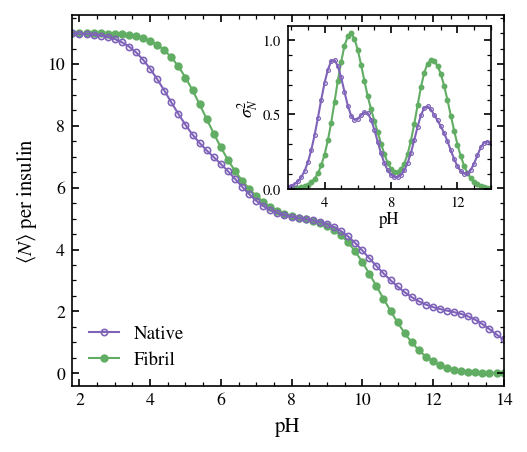

In [5]:
fig, ax = plt.subplots(figsize=(3.4, 2.9), dpi=150, layout="constrained")

ax.plot(pHs, Nav_pm["native"], marker='o', markerfacecolor='none', markeredgecolor=COLORS[0],
        color=COLORS[0], markeredgewidth=0.8, markersize=3, lw=1.0, label='Native')
ax.plot(pHs, Nav_pm["fibril"], marker='o', color=COLORS[1], markersize=3, lw=1.0, label='Fibril', zorder=-10)
ax.fill_between(pHs, tit_lo[0], tit_hi[0], color=COLORS[0], alpha=0.25, lw=0)
ax.fill_between(pHs, tit_lo[1], tit_hi[1], color=COLORS[1], alpha=0.25, lw=0)
ax.set_xlabel('pH', fontsize=10)
ax.set_ylabel(r'$\langle N \rangle$ per insulin', fontsize=10)
ax.set_xlim(min(pHs), max(pHs))
ax.set_ylim(-0.4, 11.6)
ax.xaxis.set_major_locator(MultipleLocator(2))
ax.minorticks_on()
ax.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=8.5)
ax.legend(loc='lower left', frameon=False, fontsize=9, handlelength=1.6)

# inset: the protonation variance per molecule, in the empty upper right corner
axin = ax.inset_axes([0.50, 0.53, 0.47, 0.44])
axin.plot(pHs, Var_pm["native"], color=COLORS[0], lw=1.0, marker='o', markerfacecolor='none',
          markeredgecolor=COLORS[0], markeredgewidth=0.6, markersize=1.8)
axin.plot(pHs, Var_pm["fibril"], color=COLORS[1], lw=1.0, marker='o', markersize=1.8, zorder=-10)
axin.fill_between(pHs, tit_lo[3], tit_hi[3], color=COLORS[0], alpha=0.25, lw=0)
axin.fill_between(pHs, tit_lo[4], tit_hi[4], color=COLORS[1], alpha=0.25, lw=0)
axin.set_xlim(min(pHs), max(pHs))
axin.set_ylim(0.0, 1.05 * max(Var_pm["native"].max(), Var_pm["fibril"].max()))
axin.xaxis.set_major_locator(MultipleLocator(4))
axin.yaxis.set_major_locator(MultipleLocator(0.5))
axin.minorticks_on()
axin.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=7)
axin.set_xlabel('pH', fontsize=8, labelpad=1)
axin.set_ylabel(r'$\sigma^2_N$', fontsize=8.5, labelpad=1)

fig.savefig(f"{FIG_DIR}/Titration_curves.pdf", bbox_inches='tight')
plt.show()

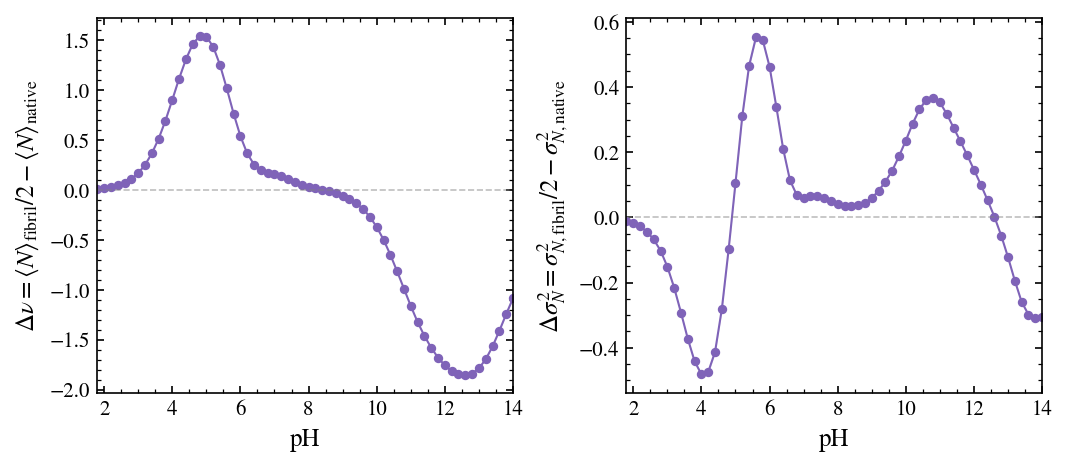

In [6]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7.0, 3.0), dpi=150, layout="constrained")

axes[0].plot(pHs, dnu, marker='o', color=COLORS[0], markersize=3.5, lw=1.0)
axes[0].fill_between(pHs, tit_lo[2], tit_hi[2], color=COLORS[0], alpha=0.25, lw=0)
axes[0].set_ylabel(r'$\Delta\nu = \langle N\rangle_{\mathrm{fibril}}/2 - \langle N\rangle_{\mathrm{native}}$', fontsize=12)

axes[1].plot(pHs, dvar, marker='o', color=COLORS[0], markersize=3.5, lw=1.0)
axes[1].fill_between(pHs, tit_lo[5], tit_hi[5], color=COLORS[0], alpha=0.25, lw=0)
axes[1].set_ylabel(r'$\Delta\sigma^2_N = \sigma^2_{N,\mathrm{fibril}}/2 - \sigma^2_{N,\mathrm{native}}$', fontsize=12)

for ax in axes:
    ax.axhline(0.0, linestyle='dashed', alpha=0.5, color='gray', lw=0.8)
    ax.minorticks_on()
    ax.set_xlabel('pH', fontsize=12)
    ax.set_xlim(min(pHs), max(pHs))
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=10)

fig.savefig(f"{FIG_DIR}/Differential_titration.pdf", bbox_inches='tight')
plt.show()

### Aggregated histograms, `PRIME_Histograms.pdf` (Fig. S1), and the distributions $\Pr(N \mid \mathrm{pH})$, `Protonation_Landscape.pdf` (Fig. S2)

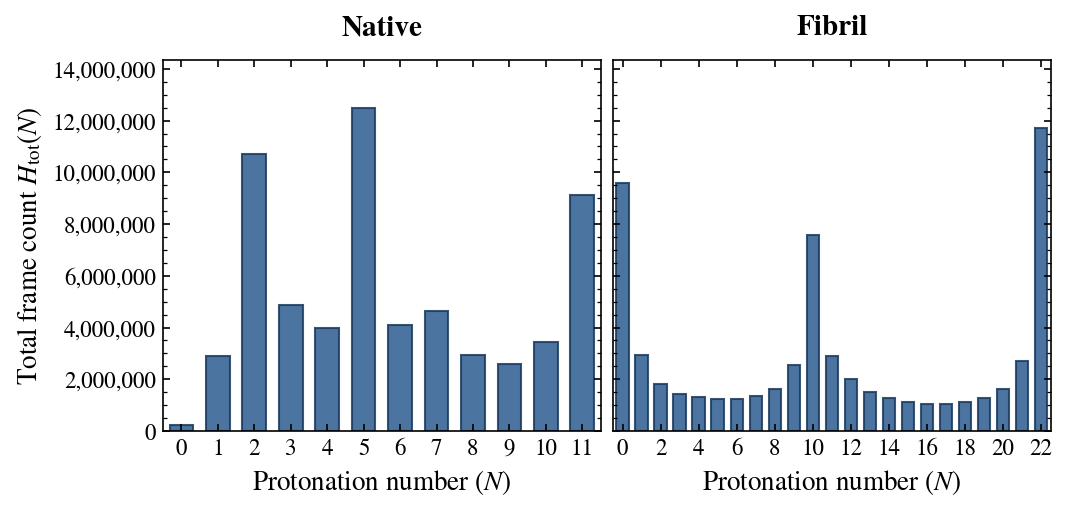

In [7]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7.0, 3.3), sharey=True, dpi=150, layout="constrained")
H_tot = {s: H[s].sum(axis=0) for s in STATES}
top = max(H_tot[s].max() for s in STATES)
for ax, s, title in zip(axes, STATES, ("Native", "Fibril")):
    N_vals = np.arange(len(H_tot[s]))
    ax.bar(N_vals, H_tot[s], color='#2b5c8f', edgecolor='#1a3a5c', width=0.65, alpha=0.85)
    ax.set_title(title, fontsize=14, pad=12, weight='bold')
    ax.set_xlabel('Protonation number ($N$)', fontsize=13)
    ax.set_xticks(N_vals if len(N_vals) <= 15 else N_vals[::2])
    ax.set_xlim(-0.5, len(N_vals) - 0.5)
    ax.set_ylim(0, top * 1.15)
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, pos: f'{int(x):,}'))
    ax.minorticks_on()
    ax.tick_params(axis='x', which='minor', length=0, width=0)
    ax.tick_params(axis='both', which='both', direction='in', left=True, right=True, bottom=True, top=True, labelsize=11)
axes[0].set_ylabel(r'Total frame count $H_{\mathrm{tot}}(N)$', fontsize=13)
fig.savefig(f"{FIG_DIR}/PRIME_Histograms.pdf", bbox_inches='tight')
plt.show()

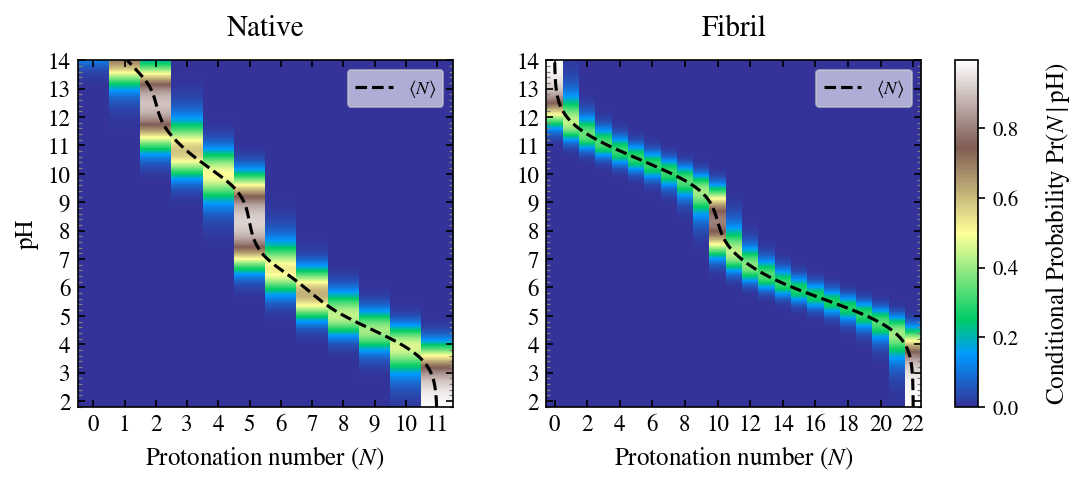

In [8]:
pH_fine = np.linspace(pHs.min(), pHs.max(), 500)
landscapes = []
for s, title in zip(STATES, ("Native", "Fibril")):
    n_values = np.arange(N_SITES[s] + 1)
    P = (H[s] / mom[s].M[:, None]).T                                   # Pr(N | pH_k), N down the rows
    Z = np.stack([interp1d(pHs, P[i], kind='cubic', bounds_error=False, fill_value='extrapolate')(pH_fine)
                  for i in range(len(n_values))])                       # interpolated along pH only
    Z = np.clip(Z, 0.0, 1.0)
    Z /= Z.sum(axis=0)
    landscapes.append((n_values, Z, (n_values[:, None] * Z).sum(axis=0), title))

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7.5, 3.3), dpi=150)
vmax = max(np.nanmax(Z) for _, Z, _, _ in landscapes)
x_edges = np.linspace(pH_fine.min(), pH_fine.max(), len(pH_fine) + 1)
for ax, (n_values, Z, mean_N, title) in zip(axes, landscapes):
    max_N = int(n_values[-1])
    mesh = ax.pcolormesh(np.arange(-0.5, max_N + 1.5, 1.0), x_edges, Z.T, cmap="terrain", vmin=0.0, vmax=vmax,
                         shading='flat', rasterized=True)
    ax.plot(mean_N, pH_fine, color="black", linestyle="--", linewidth=1.5, label=r"$\langle N \rangle$")
    ax.legend(loc="upper right", framealpha=0.6, fontsize=9)
    ax.set_title(title, fontsize=14, pad=12)
    ax.set_xlabel("Protonation number ($N$)", fontsize=12)
    ax.set_ylim(pHs.min(), pHs.max())
    ax.set_xlim(-0.5, max_N + 0.5)
    ax.set_xticks(n_values if max_N <= 12 else n_values[::2])
    ax.yaxis.set_major_locator(MultipleLocator(1.0))
    ax.yaxis.set_minor_locator(MultipleLocator(0.2))
    ax.tick_params(axis='both', which='major', labelsize=11, direction='in')
    ax.tick_params(axis='y', which='minor', color='gray', direction='in')
    ax.xaxis.set_ticks_position('both')
    ax.yaxis.set_ticks_position('both')
axes[0].set_ylabel("pH", fontsize=12)
fig.subplots_adjust(left=0.10, right=0.85, bottom=0.15, top=0.85, wspace=0.25)
cbar = fig.colorbar(mesh, cax=fig.add_axes([0.88, 0.15, 0.02, 0.7]))
cbar.set_label(r'Conditional Probability $\Pr(N \mid \mathrm{pH})$', fontsize=12, labelpad=12)
fig.savefig(f"{FIG_DIR}/Protonation_Landscape.pdf", bbox_inches='tight', dpi=300)
plt.show()

### Site-resolved apparent p$K_\mathrm{a}$ values (Table S1)

Every residue's protonated fraction is fitted with $f = [1 + 10^{\,n(\mathrm{pH} - \mathrm{p}K_\mathrm{a})}]^{-1}$ over the windows in which $0.01 < f < 0.99$. The block averages of the protonated fractions are kept for Section 3, where the restraint weights are compared residue by residue.

In [9]:
def _hh(pH, pKa, n):
    return 1.0 / (1.0 + 10.0 ** (n * (pH - pKa)))


def site_pka(f):
    '''Apparent pKa and Hill coefficient of one residue from its protonated fraction at every window.'''
    m = (f > 0.01) & (f < 0.99)
    if f.min() > 0.5:
        return np.nan, np.nan, "$>14$"
    if f.max() < 0.5:
        return np.nan, np.nan, "$<1.8$"
    if m.sum() < 4:
        return np.nan, np.nan, "n/a"
    p0 = [float(np.interp(0.5, f[m][::-1], pHs[m][::-1])), 1.0]
    try:
        (pKa, n), _ = curve_fit(_hh, pHs[m], f[m], p0=p0, maxfev=20000)
    except RuntimeError:
        return np.nan, np.nan, "no fit"
    return pKa, n, f"{pKa:.2f}"


res_blocks = {s: load_residue_blocks(PATH[s], pHs, resnames * NMOL[s], fraction=2 / 3) for s in STATES}   # (K, 100, n_res)
f_res = {s: res_blocks[s].mean(axis=1) for s in STATES}                                                    # (K, n_res)
pka_res = {s: [site_pka(f_res[s][:, i]) for i in range(f_res[s].shape[1])] for s in STATES}

print("Table S1, one row per residue: native, fibril molecule 1, fibril molecule 2 (pKa, Hill coefficient)")
for i, lab in enumerate(RES_LABELS):
    row = [lab]
    for pKa, n, txt in (pka_res["native"][i], pka_res["fibril"][i], pka_res["fibril"][i + len(resnames)]):
        row += [txt, f"{n:.2f}" if np.isfinite(n) else "--"]
    print(" & ".join(row) + r" \\")
for s in STATES:
    for cls in ("Glu", "His", "Tyr", "Lys"):
        vals = [pka_res[s][i][0] for i in range(len(pka_res[s])) if RES_LABELS[i % len(resnames)].startswith(cls)
                and np.isfinite(pka_res[s][i][0])]
        print(f"{s} {cls}: pKa {min(vals):.2f} to {max(vals):.2f}" if vals else f"{s} {cls}: none within the range")

Table S1, one row per residue: native, fibril molecule 1, fibril molecule 2 (pKa, Hill coefficient)
Glu A4 & 4.64 & 0.96 & 5.17 & 0.95 & 5.53 & 0.94 \\
Tyr A14 & 9.91 & 0.99 & 10.04 & 1.00 & 10.44 & 0.74 \\
Glu A17 & 4.03 & 0.88 & 5.71 & 0.93 & 5.13 & 0.92 \\
Tyr A19 & $>14$ & -- & 11.05 & 1.03 & 10.36 & 0.82 \\
His B5 & 6.44 & 1.06 & 5.96 & 0.95 & 5.94 & 0.92 \\
His B10 & 6.72 & 0.95 & 7.04 & 0.98 & 6.93 & 0.97 \\
Glu B13 & 4.42 & 0.92 & 5.69 & 0.92 & 5.81 & 0.94 \\
Tyr B16 & 11.18 & 1.00 & 10.23 & 1.00 & 10.55 & 0.90 \\
Glu B21 & 4.85 & 0.88 & 5.25 & 0.93 & 4.75 & 0.95 \\
Tyr B26 & 13.60 & 1.19 & 11.06 & 0.68 & 10.91 & 0.86 \\
Lys B29 & 10.15 & 0.99 & 10.95 & 0.64 & 10.22 & 0.81 \\
native Glu: pKa 4.03 to 4.85
native His: pKa 6.44 to 6.72
native Tyr: pKa 9.91 to 13.60
native Lys: pKa 10.15 to 10.15
fibril Glu: pKa 4.75 to 5.81
fibril His: pKa 5.94 to 7.04
fibril Tyr: pKa 10.04 to 11.06
fibril Lys: pKa 10.22 to 10.95


## 3. Free energy of the native-to-fibril transition

### The three estimators on the finest grid

In [10]:
# PRIME, the trapezoidal rule and the Hermite rule of TI, relative to the window at pH 1.8
dY = {s: prime.estimator_profiles(H[s], pHs) for s in STATES}                                # (3, K) per simulated system
ddY = dY["fibril"] / NMOL["fibril"] - dY["native"] / NMOL["native"]                          # per insulin molecule
EST = ("PRIME", "trapezoid", "Hermite")

for s in STATES:
    g = dY[s][0]
    d = prime.connectivity_diagnostics(g, H[s], pHs)
    sigma_g = prime.compute_prime_errors(g, H[s], pHs)[0]
    print(f"{s}: {d['n_components']} component, algebraic connectivity {d['algebraic_connectivity']:.3e}, "
          f"asymptotic sigma up to {sigma_g.max():.4f}; largest |PRIME - trapezoid| {np.abs(g - dY[s][1]).max():.4f}, "
          f"|PRIME - Hermite| {np.abs(g - dY[s][2]).max():.4f} kT")
sig_ddY = np.sqrt((prime.compute_prime_errors(dY["fibril"][0], H["fibril"], pHs)[0] / NMOL["fibril"]) ** 2
                  + prime.compute_prime_errors(dY["native"][0], H["native"], pHs)[0] ** 2)
print(f"transition: asymptotic 95% half-width of PRIME up to {1.96 * sig_ddY.max():.4f} kT")

native: 1 component, algebraic connectivity 3.053e+04, asymptotic sigma up to 0.0025; largest |PRIME - trapezoid| 0.0583, |PRIME - Hermite| 0.0630 kT
fibril: 1 component, algebraic connectivity 1.178e+04, asymptotic sigma up to 0.0035; largest |PRIME - trapezoid| 0.0403, |PRIME - Hermite| 0.0118 kT
transition: asymptotic 95% half-width of PRIME up to 0.0061 kT


### Block bootstrap of the profiles and of the residuals between the estimators

Every resample is analyzed by all three estimators, so the residual PRIME $-$ TI gets its own interval, much narrower than those of the profiles.

In [11]:
boot = {}
for s in STATES:
    boot[s] = prime.bootstrap(h_blk[s], pHs, prime.estimator_profiles, n_boot=1000, nprocs=NPROCS)
boot["transition"] = prime.bootstrap([h_blk["native"], h_blk["fibril"]], pHs, prime.transition_profiles,
                                     n_boot=1000, nprocs=NPROCS, nmol=(NMOL["native"], NMOL["fibril"]))


def interval(boots, ci=0.95):
    a = 100 * (1 - ci) / 2
    return np.percentile(boots, a, axis=0), np.percentile(boots, 100 - a, axis=0)


resid_ci = {}
for name in (*STATES, "transition"):
    nominal, boots, lo, hi = boot[name]
    scale = 1.0 if name == "transition" else 1.0 / NMOL[name]
    print(f"{name}: {len(boots)} of 1000 resamples; 95% half-width of the profiles up to "
          + ", ".join(f"{e} {0.5 * scale * (hi[i] - lo[i]).max():.4f}" for i, e in enumerate(EST)) + " kT")
    resid_ci[name] = {}
    for i, e in ((1, "trapezoid"), (2, "Hermite")):
        r = scale * (nominal[0] - nominal[i])
        r_lo, r_hi = interval(scale * (boots[:, 0] - boots[:, i]))
        resid_ci[name][e] = (r, r_lo, r_hi)
        k = int(np.argmax(np.abs(r)))
        print(f"   PRIME - {e:>9}: {r[k]:+.4f} kT at pH {pHs[k]:.1f}, interval [{r_lo[k]:+.4f}, {r_hi[k]:+.4f}], "
              f"half-width up to {0.5 * (r_hi - r_lo).max():.4f}")

native: 1000 of 1000 resamples; 95% half-width of the profiles up to PRIME 0.0100, trapezoid 0.0101, Hermite 0.0101 kT
   PRIME - trapezoid: -0.0583 kT at pH 13.4, interval [-0.0600, -0.0567], half-width up to 0.0021
   PRIME -   Hermite: -0.0630 kT at pH 13.4, interval [-0.0647, -0.0614], half-width up to 0.0021
fibril: 1000 of 1000 resamples; 95% half-width of the profiles up to PRIME 0.0084, trapezoid 0.0085, Hermite 0.0085 kT
   PRIME - trapezoid: +0.0202 kT at pH 5.4, interval [+0.0191, +0.0212], half-width up to 0.0011
   PRIME -   Hermite: +0.0059 kT at pH 4.4, interval [+0.0051, +0.0067], half-width up to 0.0010
transition: 1000 of 1000 resamples; 95% half-width of the profiles up to PRIME 0.0135, trapezoid 0.0136, Hermite 0.0136 kT
   PRIME - trapezoid: +0.0588 kT at pH 13.4, interval [+0.0571, +0.0605], half-width up to 0.0022
   PRIME -   Hermite: +0.0632 kT at pH 13.4, interval [+0.0615, +0.0648], half-width up to 0.0022


### Semi-grand free energies of the two states, `Absolute_Free_Energies.pdf` (Fig. S4)

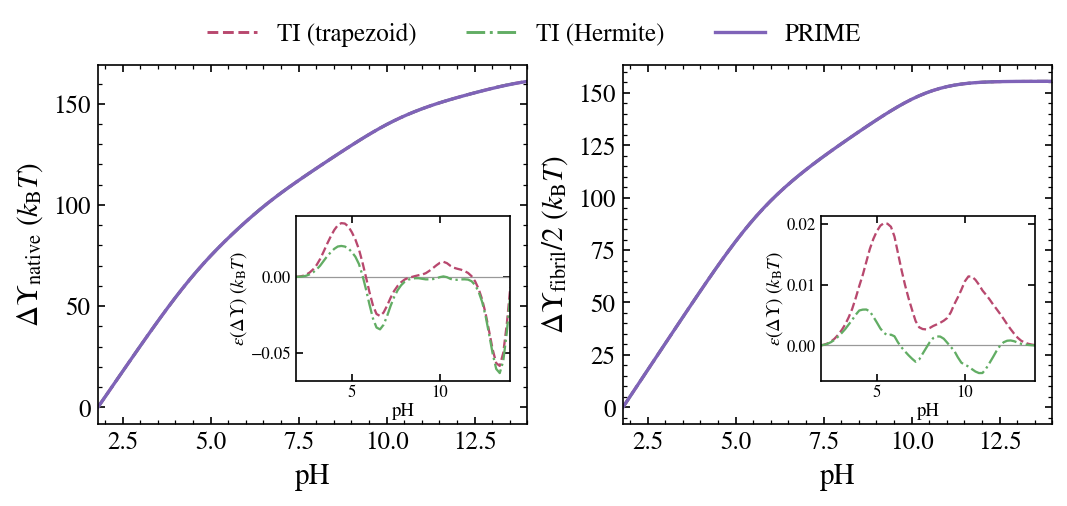

In [12]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(7.0, 3.3), dpi=150, layout="constrained")
labels = {"native": r'$\Delta \Upsilon_{\mathrm{native}}$ $(k_\mathrm{B}T)$',
          "fibril": r'$\Delta \Upsilon_{\mathrm{fibril}}/2$ $(k_\mathrm{B}T)$'}
for ax, s in zip(axes, STATES):
    g_prime, g_trap, g_herm = dY[s] / NMOL[s]
    ax.plot(pHs, g_trap, color=C_TRAP, lw=1.4, ls='--', label='TI (trapezoid)')
    ax.plot(pHs, g_herm, color=C_HERM, lw=1.4, ls='-.', label='TI (Hermite)')
    ax.plot(pHs, g_prime, color=C_PRIME, lw=1.6, label='PRIME')
    ax.set_ylabel(labels[s], fontsize=14)
    axin = ax.inset_axes([0.46, 0.12, 0.50, 0.46])                      # the residual between PRIME and each TI rule
    axin.axhline(0.0, color='0.6', lw=0.6)
    axin.plot(pHs, g_prime - g_trap, color=C_TRAP, lw=1.1, ls='--')
    axin.plot(pHs, g_prime - g_herm, color=C_HERM, lw=1.1, ls='-.')
    axin.set_xlim(min(pHs), max(pHs))
    axin.set_xlabel('pH', fontsize=9, labelpad=1)
    axin.set_ylabel(r'$\epsilon(\Delta\Upsilon)$ $(k_\mathrm{B}T)$', fontsize=9, labelpad=1)
    axin.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=8, pad=2)
for ax in axes:
    ax.minorticks_on()
    ax.set_xlabel('pH', fontsize=14)
    ax.set_xlim(min(pHs), max(pHs))
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=12)
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc='outside upper center', ncols=3, frameon=False, fontsize=12)
fig.savefig(f"{FIG_DIR}/Absolute_Free_Energies.pdf", bbox_inches='tight')
plt.show()

### Free energy of the transition, `Difference_in_Free_Energies.pdf` (Fig. 2)

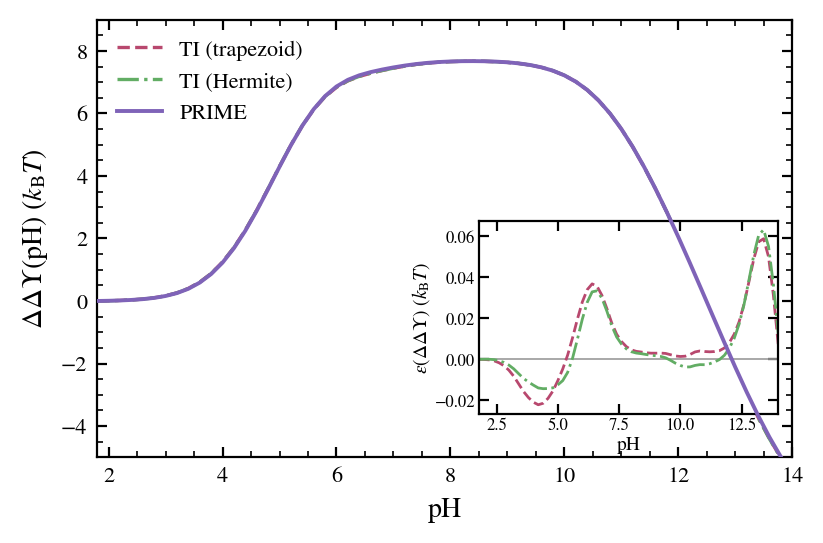

ddY(pH 3.0) = +0.16 kT
ddY(pH 6.0) = +6.86 kT
ddY(pH 8.0) = +7.66 kT
ddY(pH 12.6) = -0.45 kT
ddY(pH 14.0) = -5.55 kT


In [13]:
fig, ax = plt.subplots(figsize=(4.0, 2.6), dpi=200, layout="constrained")
ax.plot(pHs, ddY[1], color=C_TRAP, lw=1.2, ls='--', label='TI (trapezoid)')
ax.plot(pHs, ddY[2], color=C_HERM, lw=1.2, ls='-.', label='TI (Hermite)')
ax.plot(pHs, ddY[0], color=C_PRIME, lw=1.4, label='PRIME', zorder=11)

axin = ax.inset_axes([0.55, 0.10, 0.43, 0.44])
axin.axhline(0.0, color='0.6', lw=0.6)
axin.plot(pHs, ddY[0] - ddY[1], color=C_TRAP, lw=1.0, ls='--')
axin.plot(pHs, ddY[0] - ddY[2], color=C_HERM, lw=1.0, ls='-.')
axin.set_xlim(min(pHs), max(pHs))
axin.set_xlabel('pH', fontsize=7, labelpad=1)
axin.set_ylabel(r'$\epsilon(\Delta\Delta\Upsilon)$ $(k_\mathrm{B}T)$', fontsize=7, labelpad=1)
axin.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=6, pad=1.5)

ax.set_ylabel(r'$\Delta\Delta \Upsilon(\mathrm{pH})$ $(k_\mathrm{B}T)$', fontsize=10)
ax.set_xlabel('pH', fontsize=10)
ax.minorticks_on()
ax.legend(loc='upper left', frameon=False, fontsize=8)
ax.set_xlim(min(pHs), max(pHs))
ax.set_ylim(-5, 9)
ax.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=8)
fig.savefig(f"{FIG_DIR}/Difference_in_Free_Energies.pdf", bbox_inches='tight')
plt.show()

for pH in (3.0, 6.0, 8.0, 12.6, 14.0):
    k = int(np.argmin(np.abs(pHs - pH)))
    print(f"ddY(pH {pHs[k]:.1f}) = {ddY[0][k]:+.2f} kT")

### Block length of the bootstrap (Table S2)

The standard error of the window mean from blocks of increasing length rises until the blocks are longer than the slowest correlated mode. The ratio to its value at the bootstrap block, median and largest over the windows.

In [14]:
lengths = [BLOCK * 2 ** i for i in range(8)]
print("L (frames)" + "".join(f" & {L}" for L in lengths) + r" \\")
for s in STATES:
    se = np.array([prime.blocking_scan(data[s][pH]["N"], lengths)[1] for pH in pHs])
    ratio = se / se[:, [0]]
    for name, row in (("median", np.nanmedian(ratio, axis=0)), ("maximum", np.nanmax(ratio, axis=0))):
        print(f"{s.capitalize()}, {name}" + "".join(f" & {r:.2f}" for r in row) + r" \\")

L (frames) & 438 & 876 & 1752 & 3504 & 7008 & 14016 & 28032 & 56064 \\
Native, median & 1.00 & 1.08 & 1.19 & 1.36 & 1.52 & 1.79 & 1.95 & 2.36 \\
Native, maximum & 1.00 & 1.28 & 1.63 & 2.00 & 2.50 & 2.95 & 3.49 & 4.48 \\
Fibril, median & 1.00 & 1.12 & 1.29 & 1.50 & 1.75 & 2.07 & 2.43 & 2.97 \\
Fibril, maximum & 1.00 & 1.24 & 1.58 & 2.05 & 2.63 & 3.33 & 4.11 & 5.14 \\


### Halves and quarters of the trajectories, `Convergence_quarters.pdf` (Fig. S5) and Table S3

The profiles from each quarter of every window alone, against the full trajectory, and the difference between the two halves.

second half - first half
     <N> native: at pH 8 -0.001, at pH 14 -0.049, largest |d| 0.049 at pH 14.0
   <N> fibril/2: at pH 8 +0.000, at pH 14 +0.000, largest |d| 0.052 at pH 11.0
      dY native: at pH 8 -0.090, at pH 14 -0.202, largest |d| 0.202 at pH 14.0
    dY fibril/2: at pH 8 -0.046, at pH 14 +0.167, largest |d| 0.167 at pH 14.0
            ddY: at pH 8 +0.044, at pH 14 +0.369, largest |d| 0.369 at pH 14.0

Table S3
Full & 5.739 & 5.536 & 161.06 & 155.52 & 7.66 & $-5.55$ \\
Quarter 1 & 5.742 & 5.533 & 161.15 & 155.44 & 7.68 & $-5.71$ \\
Quarter 2 & 5.743 & 5.532 & 161.18 & 155.43 & 7.60 & $-5.75$ \\
Quarter 3 & 5.737 & 5.542 & 161.02 & 155.71 & 7.74 & $-5.31$ \\
Quarter 4 & 5.733 & 5.535 & 160.91 & 155.49 & 7.63 & $-5.42$ \\
ddY(8): full 7.66, quarters 7.60 to 7.74, largest |quarter - full| 0.08 kT
ddY(14): full -5.55, quarters -5.75 to -5.31, largest |quarter - full| 0.24 kT


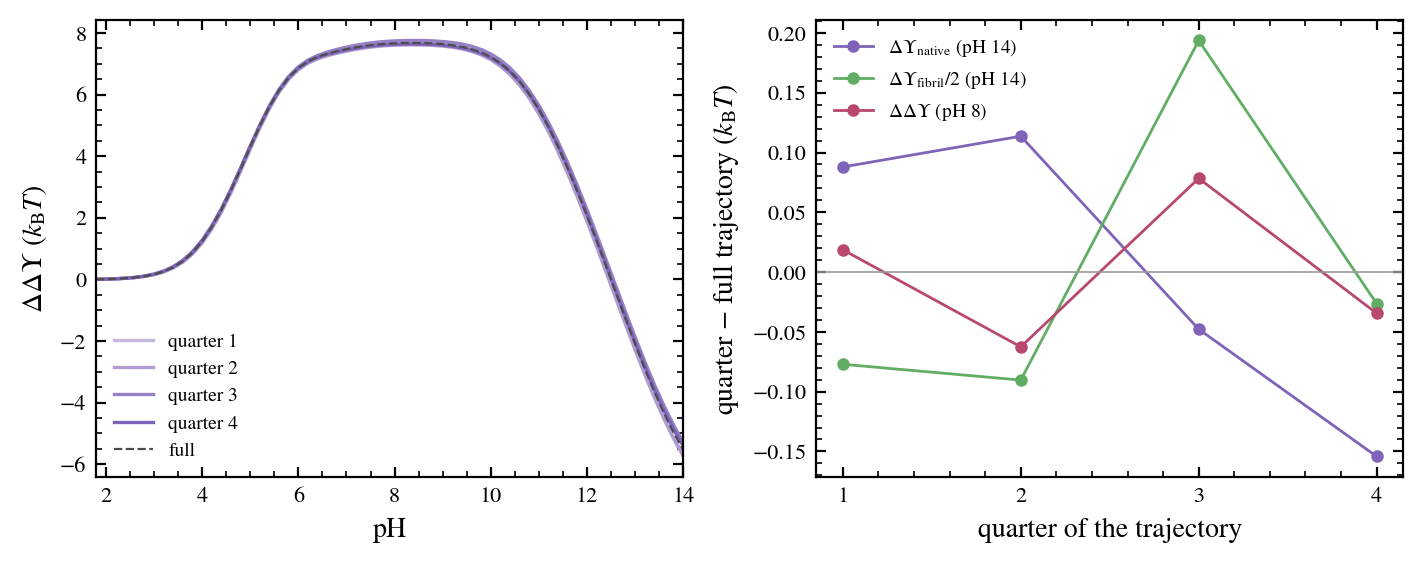

In [15]:
def prime_profile(Hs):
    '''PRIME profile per molecule of both states and the transition, relative to pH 1.8, from one histogram per state.'''
    gN = prime.estimator_profiles(Hs["native"], pHs)[0] / NMOL["native"]
    gF = prime.estimator_profiles(Hs["fibril"], pHs)[0] / NMOL["fibril"]
    return dict(dY_native=gN, dY_fibril=gF, ddY=gF - gN,
                N_native=prime.histogram_moments(Hs["native"]).mean / NMOL["native"],
                N_fibril=prime.histogram_moments(Hs["fibril"]).mean / NMOL["fibril"])


full = prime_profile(H)
halves = [prime_profile({s: prime.partial_histograms(h_blk[s], 2)[i] for s in STATES}) for i in range(2)]
quarters = [prime_profile({s: prime.partial_histograms(h_blk[s], 4)[i] for s in STATES}) for i in range(4)]
k8, k14 = int(np.argmin(np.abs(pHs - 8.0))), K - 1

print("second half - first half")
for key, name in (("N_native", "<N> native"), ("N_fibril", "<N> fibril/2"), ("dY_native", "dY native"),
                  ("dY_fibril", "dY fibril/2"), ("ddY", "ddY")):
    d = halves[1][key] - halves[0][key]
    print(f"  {name:>13}: at pH 8 {d[k8]:+.3f}, at pH 14 {d[k14]:+.3f}, largest |d| {np.abs(d).max():.3f} at pH {pHs[np.argmax(np.abs(d))]:.1f}")

print("\nTable S3")
for name, r in (("Full", full), *((f"Quarter {i + 1}", q) for i, q in enumerate(quarters))):
    print(f"{name} & {r['N_native'].mean():.3f} & {r['N_fibril'].mean():.3f} & {r['dY_native'][k14]:.2f} & "
          f"{r['dY_fibril'][k14]:.2f} & {r['ddY'][k8]:.2f} & ${r['ddY'][k14]:.2f}$ \\\\")
for key, kk, name in (("ddY", k8, "ddY(8)"), ("ddY", k14, "ddY(14)")):
    vals = [q[key][kk] for q in quarters]
    print(f"{name}: full {full[key][kk]:.2f}, quarters {min(vals):.2f} to {max(vals):.2f}, "
          f"largest |quarter - full| {max(abs(v - full[key][kk]) for v in vals):.2f} kT")

fig, ax = plt.subplots(1, 2, figsize=(7.0, 2.7), dpi=200, layout="constrained")
base = np.array(mcolors.to_rgb(COLORS[0]))
for i, q in enumerate(quarters):
    frac = 0.55 * (3 - i) / 3
    ax[0].plot(pHs, q["ddY"], lw=1.2, color=tuple(base + (1 - base) * frac), label=f"quarter {i + 1}")
ax[0].plot(pHs, full["ddY"], lw=0.8, ls="--", color="0.3", label="full")
ax[0].set_ylabel(r"$\Delta\Delta\Upsilon$ $(k_\mathrm{B}T)$", fontsize=10)
ax[0].set_xlabel("pH", fontsize=10)
ax[0].set_xlim(pHs.min(), pHs.max())
ax[0].legend(frameon=False, fontsize=7)
qx = np.arange(1, 5)
for key, kk, name, col in (("dY_native", k14, r"$\Delta\Upsilon_\mathrm{native}$ (pH 14)", COLORS[0]),
                           ("dY_fibril", k14, r"$\Delta\Upsilon_\mathrm{fibril}/2$ (pH 14)", COLORS[1]),
                           ("ddY", k8, r"$\Delta\Delta\Upsilon$ (pH 8)", COLORS[2])):
    ax[1].plot(qx, [q[key][kk] - full[key][kk] for q in quarters], "o-", ms=3.5, lw=1.0, color=col, label=name)
ax[1].axhline(0, color="0.6", lw=0.6)
ax[1].set_xticks(qx)
ax[1].set_xlabel("quarter of the trajectory", fontsize=10)
ax[1].set_ylabel(r"quarter $-$ full trajectory $(k_\mathrm{B}T)$", fontsize=10)
ax[1].legend(frameon=False, fontsize=7)
for a in ax:
    a.minorticks_on()
    a.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=8)
fig.savefig(f"{FIG_DIR}/Convergence_quarters.pdf", bbox_inches='tight')
plt.show()

### Decomposition of the PRIME–TI residual, `Residual_decomposition.pdf` (Fig. S6)

TI integrates the sampled means of the windows. Evaluated a second time with the means and variances implied by the PRIME solution, the residual splits exactly into a quadrature part, which must equal the Euler–Maclaurin bias, and a consistency part, which is zero only if every window agrees with the weights fitted to all windows together.

native: residual against the trapezoidal rule -0.0583 kT at pH 13.4 = quadrature +0.0048 + consistency -0.0631; against the Hermite rule -0.0630 at pH 13.4
   |quadrature - Euler-Maclaurin| up to 0.00056 (trapezoid), |quadrature| up to 0.000014 kT (Hermite)
   implied - sampled mean: up to 0.0549 protons at pH 14.0, RMS 0.0141
fibril: residual against the trapezoidal rule +0.0202 kT at pH 5.4 = quadrature +0.0179 + consistency +0.0023; against the Hermite rule +0.0059 at pH 4.4
   |quadrature - Euler-Maclaurin| up to 0.00028 (trapezoid), |quadrature| up to 0.000015 kT (Hermite)
   implied - sampled mean: up to 0.0032 protons at pH 9.6, RMS 0.0014
transition: residual against the trapezoidal rule +0.0588 kT at pH 13.4 = quadrature -0.0045 + consistency +0.0632; against the Hermite rule +0.0632 at pH 13.4
   |quadrature - Euler-Maclaurin| up to 0.00056 (trapezoid), |quadrature| up to 0.000025 kT (Hermite)
   implied - sampled mean: up to 0.0550 protons at pH 14.0, RMS 0.0139
native: RMS 

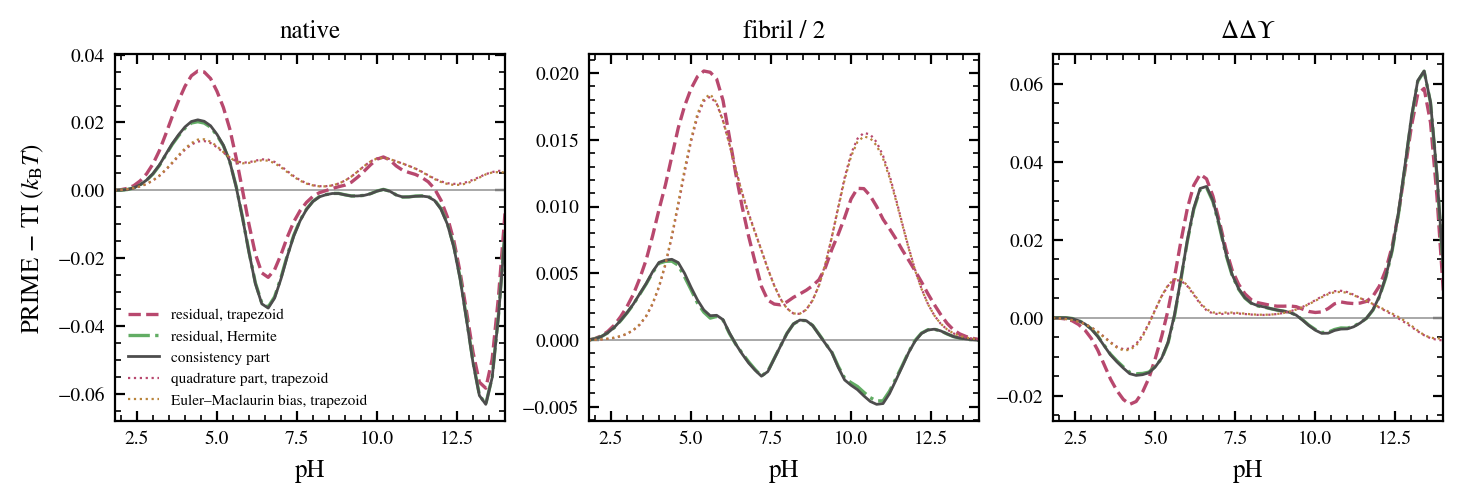

In [16]:
split = {}
for s in STATES:
    r = prime.residual_decomposition(H[s], pHs)
    split[s] = {key: val / NMOL[s] for key, val in r.items()}
split["transition"] = {key: split["fibril"][key] - split["native"][key] for key in split["native"]}

for name, r in split.items():
    tot_t, tot_h = r["prime"] - r["trapezoid"], r["prime"] - r["hermite"]
    k, kh = int(np.argmax(np.abs(tot_t))), int(np.argmax(np.abs(tot_h)))
    print(f"{name}: residual against the trapezoidal rule {tot_t[k]:+.4f} kT at pH {pHs[k]:.1f} "
          f"= quadrature {r['quadrature_trapezoid'][k]:+.4f} + consistency {r['consistency'][k]:+.4f}; "
          f"against the Hermite rule {tot_h[kh]:+.4f} at pH {pHs[kh]:.1f}")
    print(f"   |quadrature - Euler-Maclaurin| up to {np.abs(r['quadrature_trapezoid'] - r['bias_trapezoid']).max():.5f} (trapezoid), "
          f"|quadrature| up to {np.abs(r['quadrature_hermite']).max():.6f} kT (Hermite)")
    j = int(np.argmax(np.abs(r["dN"])))
    print(f"   implied - sampled mean: up to {np.abs(r['dN'][j]):.4f} protons at pH {pHs[j]:.1f}, RMS {np.sqrt(np.mean(r['dN'] ** 2)):.4f}")

# the disagreement of the window means in units of their own block standard errors
for s in STATES:
    bm = prime.block_means(h_blk[s])
    se = bm.std(axis=1, ddof=1) / np.sqrt(bm.shape[1])
    z = prime.residual_decomposition(H[s], pHs)["dN"] / se
    print(f"{s}: RMS z {np.sqrt(np.mean(z ** 2)):.1f}, largest |z| {np.abs(z).max():.1f} at pH {pHs[np.argmax(np.abs(z))]:.1f}")

fig, ax = plt.subplots(1, 3, figsize=(7.2, 2.4), dpi=200, layout="constrained")
for a, (name, title) in zip(ax, (("native", "native"), ("fibril", "fibril / 2"), ("transition", r"$\Delta\Delta\Upsilon$"))):
    r = split[name]
    a.axhline(0, color="0.6", lw=0.6)
    a.plot(pHs, r["prime"] - r["trapezoid"], color=C_TRAP, lw=1.2, ls="--", label="residual, trapezoid")
    a.plot(pHs, r["prime"] - r["hermite"], color=C_HERM, lw=1.2, ls="-.", label="residual, Hermite")
    a.plot(pHs, r["consistency"], color="0.3", lw=1.0, label="consistency part")
    a.plot(pHs, r["quadrature_trapezoid"], color=C_TRAP, lw=0.8, ls=":", label="quadrature part, trapezoid")
    a.plot(pHs, r["bias_trapezoid"], color=COLORS[3], lw=0.8, ls=":", label="Euler–Maclaurin bias, trapezoid")
    a.set_title(title, fontsize=9)
    a.set_xlabel("pH", fontsize=9)
    a.set_xlim(pHs.min(), pHs.max())
    a.minorticks_on()
    a.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=7)
ax[0].set_ylabel(r"PRIME $-$ TI $(k_\mathrm{B}T)$", fontsize=9)
ax[0].legend(frameon=False, fontsize=5.5, loc="best")
fig.savefig(f"{FIG_DIR}/Residual_decomposition.pdf", bbox_inches="tight")
plt.show()

### Restraint weight of the monomer (Table S4)

The monomer at the other restraint weights is loaded one at a time. For every run, the free energy of the transition from the full trajectory and from its four quarters, the drift of $\langle N\rangle$ over the quarters, and the consistency test of Section 6, whose result is kept for the comparison there.

In [17]:
k8, k14 = int(np.argmin(np.abs(pHs - 8.0))), K - 1
fib_full = prime.estimator_profiles(H["fibril"], pHs)[0] / NMOL["fibril"]
fib_quarters = [prime.estimator_profiles(Hq, pHs)[0] / NMOL["fibril"] for Hq in prime.partial_histograms(h_blk["fibril"], 4)]

runs = {}
for w in sorted(PATH_NATIVE_WEIGHTS, reverse=True):
    if w == 10:
        data_w = data["native"]
    elif os.path.isdir(PATH_NATIVE_WEIGHTS[w]):
        data_w = load_protonation_counts(PATH_NATIVE_WEIGHTS[w], pHs, resnames, fraction=2 / 3)
    else:
        print(f"weight {w}: {PATH_NATIVE_WEIGHTS[w]} not found, skipped")
        continue
    Hw = prime.build_histograms(data_w, pHs, n_sites=N_SITES["native"])
    hb_w = prime.block_histograms(data_w, pHs, block_length=BLOCK, n_sites=N_SITES["native"])
    h32_w = prime.block_histograms(data_w, pHs, n_blocks=32, n_sites=N_SITES["native"])
    dY_w = prime.estimator_profiles(Hw, pHs)[0]
    dY_q = [prime.estimator_profiles(Hq, pHs)[0] for Hq in prime.partial_histograms(hb_w, 4)]
    Nav_q = np.array([prime.histogram_moments(Hq).mean for Hq in prime.partial_histograms(hb_w, 4)])     # (4, K)
    ddY_q = np.array([fq - nq for fq, nq in zip(fib_quarters, dY_q)])
    d8 = ddY_q[:, k8]
    dN = (Nav_q[-1] - Nav_q[0]) / 3
    runs[w] = dict(dY=dY_w, ddY=fib_full - dY_w, ddY_q=ddY_q, Nav=prime.histogram_moments(Hw).mean,
                   drifting=bool(np.all(np.diff(d8) > 0) or np.all(np.diff(d8) < 0)),
                   dN_per_quarter=dN.mean(), n_rising=int((dN > 0).sum()),
                   consistency=prime.consistency_test(Hw, pHs, h32_w, n_boot=400))
    if w != 10:
        del data_w

print(f"{'weight':>7} {'ddY(8)':>7} {'quarters':>26} {'ddY(14)':>8} {'quarters':>30} {'dY(w)-dY(10) at 8, 14':>24} {'d<N>/quarter':>13} {'rising':>7}")
for w, r in runs.items():
    q8, q14 = r["ddY_q"][:, k8], r["ddY_q"][:, k14]
    rel = r["dY"] - runs[10]["dY"]
    print(f"{w:>7} {r['ddY'][k8]:>7.2f} {'(' + ', '.join(f'{v:.2f}' for v in q8) + ')':>26} "
          f"{r['ddY'][k14]:>8.2f} {'(' + ', '.join(f'{v:.2f}' for v in q14) + ')':>30} "
          f"{rel[k8]:>+11.2f} {rel[k14]:>+6.2f} {r['dN_per_quarter']:>+13.4f} {r['n_rising']:>4d}/{K}"
          f"{'   drifting' if r['drifting'] else ''}")


def tex(v):
    return f"{v:.2f}" if v >= 0 else f"${v:.2f}$"


print("\nTable S4")
for w, r in runs.items():
    q8, q14 = r["ddY_q"][:, k8], r["ddY_q"][:, k14]
    drift = ", drifting" if r["drifting"] else ""
    print(f"{'none' if w == 0 else f'{w:g}':<5} & {tex(r['ddY'][k8])} ({tex(q8.min())}--{tex(q8.max())}){drift} "
          f"& {tex(r['ddY'][k14])} ({tex(q14.min())} to {tex(q14.max())}){drift} \\\\")

 weight  ddY(8)                   quarters  ddY(14)                       quarters    dY(w)-dY(10) at 8, 14  d<N>/quarter  rising
     10    7.66   (7.68, 7.60, 7.74, 7.63)    -5.55   (-5.71, -5.75, -5.31, -5.42)       +0.00  +0.00       -0.0030   17/62
      1    8.46   (8.41, 8.36, 8.60, 8.44)    -4.24   (-4.35, -4.52, -4.02, -4.07)       -0.79  -1.31       -0.0028   11/62
    0.1    7.25   (7.29, 7.10, 7.26, 7.34)    -4.74   (-4.85, -5.08, -4.60, -4.42)       +0.42  -0.81       -0.0047   13/62
      0    5.57   (6.12, 5.69, 5.42, 5.04)    -1.12   (-0.08, -0.99, -1.21, -2.18)       +2.09  -4.43       +0.0256   62/62   drifting

Table S4
10    & 7.66 (7.60--7.74) & $-5.55$ ($-5.75$ to $-5.31$) \\
1     & 8.46 (8.36--8.60) & $-4.24$ ($-4.52$ to $-4.02$) \\
0.1   & 7.25 (7.10--7.34) & $-4.74$ ($-5.08$ to $-4.42$) \\
none  & 5.57 (5.04--6.12), drifting & $-1.12$ ($-2.18$ to $-0.08$), drifting \\


### The restraint weights residue by residue

For every run, the apparent p$K_\mathrm{a}$ of each residue, its shift between the two halves of the windows, and its contribution to $\Delta\Upsilon_\mathrm{native}(w) - \Delta\Upsilon_\mathrm{native}(10)$ at pH 8 and 14, $\ln(10)\int [f_{i,w} - f_{i,10}]\,\mathrm{d(pH)}$.

In [18]:
def _logit10(f):
    return np.log10(f / (1.0 - f))


res_w = {}
for w in runs:
    blocks = res_blocks["native"] if w == 10 else load_residue_blocks(PATH_NATIVE_WEIGHTS[w], pHs, resnames, fraction=2 / 3)
    nb = blocks.shape[1]
    f_full, f1, f2 = blocks.mean(axis=1), blocks[:, :nb // 2].mean(axis=1), blocks[:, nb // 2:].mean(axis=1)
    ok = (f1 > 0.05) & (f1 < 0.95) & (f2 > 0.05) & (f2 < 0.95)             # the windows where the residue titrates
    with np.errstate(divide='ignore', invalid='ignore'):
        dpk = np.where(ok, _logit10(f2) - _logit10(f1), np.nan)
    res_w[w] = dict(f=f_full, pka=[site_pka(f_full[:, i]) for i in range(len(resnames))], dpk=np.nanmean(dpk, axis=0))

name = {w: "none" if w == 0 else f"{w:g}" for w in runs}
print("apparent pKa (Hill coefficient) and its shift between the halves of the windows, for every restraint weight")
print(f"{'residue':>8}" + "".join(f"{name[w]:>24}" for w in runs))
for i, lab in enumerate(RES_LABELS):
    print(f"{lab:>8}" + "".join(f"{res_w[w]['pka'][i][2]:>10} ({res_w[w]['pka'][i][1]:.2f}) {res_w[w]['dpk'][i]:+.3f}"
                                 if np.isfinite(res_w[w]['pka'][i][1]) else f"{res_w[w]['pka'][i][2]:>17} {res_w[w]['dpk'][i]:+.3f}"
                                 for w in runs))

print("\ncontribution of each residue to dY_native(w) - dY_native(10) at pH 8 and 14 (kT)")
others = [w for w in runs if w != 10]
print(f"{'residue':>8}" + "".join(f"{name[w] + ' @8':>10}{'@14':>8}" for w in others))
tot = {w: np.zeros(2) for w in others}
for i, lab in enumerate(RES_LABELS):
    row = f"{lab:>8}"
    for w in others:
        df = res_w[w]["f"][:, i] - res_w[10]["f"][:, i]
        cum = np.log(10.0) * np.concatenate([[0.0], np.cumsum(0.5 * (df[1:] + df[:-1]) * np.diff(pHs))])
        tot[w] += (cum[k8], cum[k14])
        row += f"{cum[k8]:>+10.2f}{cum[k14]:>+8.2f}"
    print(row)
print(f"{'sum':>8}" + "".join(f"{tot[w][0]:>+10.2f}{tot[w][1]:>+8.2f}" for w in others))
print(f"{'PRIME':>8}" + "".join(f"{(runs[w]['dY'] - runs[10]['dY'])[k8]:>+10.2f}{(runs[w]['dY'] - runs[10]['dY'])[k14]:>+8.2f}" for w in others))

apparent pKa (Hill coefficient) and its shift between the halves of the windows, for every restraint weight
 residue                      10                       1                     0.1                    none
  Glu A4      4.64 (0.96) +0.017      4.61 (0.95) -0.016      4.68 (0.93) +0.006      4.80 (0.91) +0.097
 Tyr A14      9.91 (0.99) -0.007      9.86 (1.02) -0.005      9.86 (1.02) +0.012     10.03 (1.01) +0.034
 Glu A17      4.03 (0.88) -0.037      3.80 (0.89) -0.048      4.10 (0.87) -0.077      4.70 (0.89) +0.028
 Tyr A19            $>14$ -0.154            $>14$ +0.030            $>14$ -0.137     13.53 (0.98) +0.171
  His B5      6.44 (1.06) -0.004      6.38 (1.01) +0.005      6.49 (1.05) +0.003      6.53 (1.00) +0.097
 His B10      6.72 (0.95) -0.000      6.78 (0.95) -0.018      6.82 (0.95) -0.000      6.74 (0.93) +0.026
 Glu B13      4.42 (0.92) -0.001      4.36 (0.91) +0.001      4.29 (0.91) +0.005      4.32 (0.92) +0.004
 Tyr B16     11.18 (1.00) -0.002     11.15 (1.00) +0

## 4. Coarsening of the pH grid

### RMS error against the spacing, `Coarsening_pH_ddG.pdf` (Fig. 3) and `Coarsening_pH_dG.pdf` (Fig. S7)

The retained windows are a sub-grid of the simulated ones. All sub-grids of a spacing are evaluated and the RMS deviation from the finest-grid PRIME profile is averaged over them. Both states are coarsened onto the same windows for the transition.

transition     PRIME: dpH 1.0 0.008   2.0 0.040   2.8 0.111 kT
transition trapezoid: dpH 1.0 0.121   2.0 0.687   2.8 2.255 kT
transition   Hermite: dpH 1.0 0.014   2.0 0.432   2.8 1.478 kT
    native     PRIME: dpH 1.0 0.007   2.0 0.042   2.8 0.100 kT
    native trapezoid: dpH 1.0 0.169   2.0 0.634   2.8 1.955 kT
    native   Hermite: dpH 1.0 0.013   2.0 0.299   2.8 1.058 kT
    fibril     PRIME: dpH 1.0 0.004   2.0 0.024   2.8 0.062 kT
    fibril trapezoid: dpH 1.0 0.225   2.0 0.917   2.8 1.892 kT
    fibril   Hermite: dpH 1.0 0.006   2.0 0.163   2.8 0.732 kT


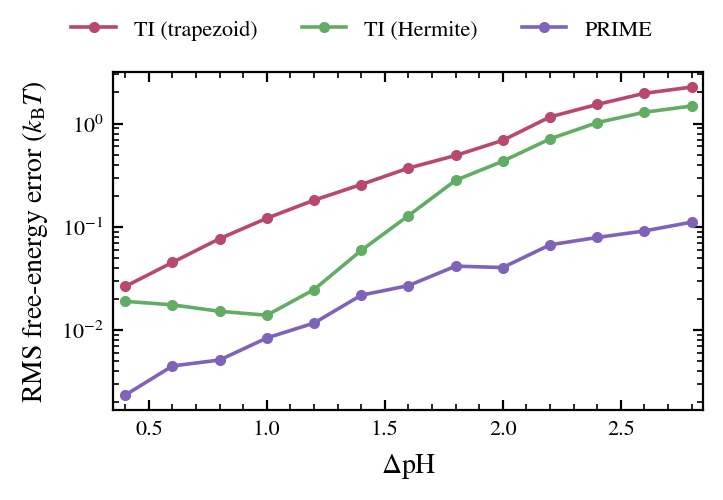

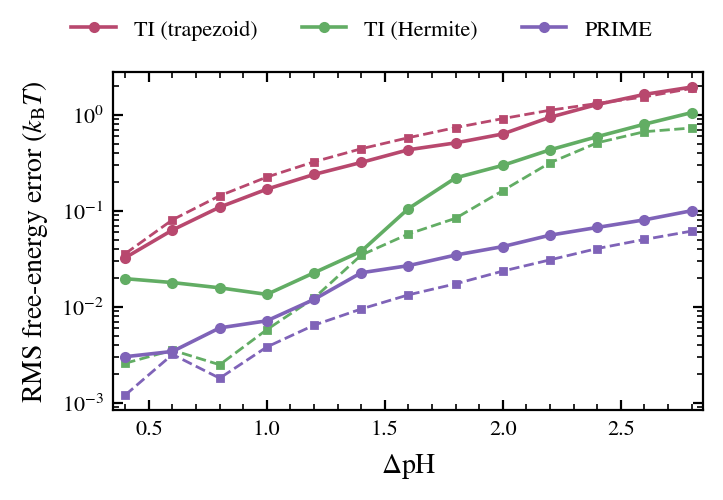

In [19]:
spacings, rms_ddY = prime.coarsening_rms([H["native"], H["fibril"]], pHs, max_step=14,
                                         weights=(-1.0 / NMOL["native"], 1.0 / NMOL["fibril"]))
rms = {s: prime.coarsening_rms(H[s], pHs, max_step=14, weights=(1.0 / NMOL[s],))[1] for s in STATES}

for name, r in (("transition", rms_ddY), *rms.items()):
    for j, e in enumerate(EST):
        print(f"{name:>10} {e:>9}: dpH 1.0 {r[j][4]:.3f}   2.0 {r[j][9]:.3f}   2.8 {r[j][13]:.3f} kT")

sl = slice(1, None)                                                  # the finest spacing is the reference itself
x = spacings[sl]
for fname, series in (("Coarsening_pH_ddG.pdf", {"": rms_ddY}), ("Coarsening_pH_dG.pdf", rms)):
    fig, ax = plt.subplots(figsize=(3.5, 2.4), dpi=200, layout="constrained")
    for j, col, nm in ((1, C_TRAP, "TI (trapezoid)"), (2, C_HERM, "TI (Hermite)"), (0, C_PRIME, "PRIME")):
        for (s, r), ls, mk, ms in zip(series.items(), ("-", "--"), ("o", "s"), (3, 2.5)):
            ax.plot(x, r[j][sl], ls, marker=mk, ms=ms, lw=1.3 if ls == "-" else 1.0, color=col, label=nm if ls == "-" else None)
    ax.set_xlabel(r"$\Delta \mathrm{pH}$", fontsize=10)
    ax.set_ylabel(r"RMS free-energy error ($k_\mathrm{B}T$)", fontsize=10)
    ax.set_yscale('log')
    ax.set_xlim(x.min() - 0.05, x.max() + 0.05)
    ax.minorticks_on()
    ax.tick_params(axis='both', which='both', direction='in', top=True, right=True, labelsize=8)
    handles, labels_ = ax.get_legend_handles_labels()
    fig.legend(handles, labels_, loc='outside upper center', ncols=3, frameon=False, fontsize=8)
    fig.savefig(f"{FIG_DIR}/{fname}", bbox_inches='tight')
    plt.show()

### The profiles on one coarse grid, `Coarse_grid_comparison.pdf` (Fig. S8)

Every tenth window ($\Delta\mathrm{pH} = 2.0$, seven windows from pH 1.8), with the Euler–Maclaurin estimates of the quadrature errors from the retained windows alone.

 dpH  windows  estimator  ddY(7.8)     dev  ddY(13.8)     dev     RMS
 0.2       62      PRIME      7.65   +0.00      -4.99   +0.00   0.000
 0.2       62  trapezoid      7.64   -0.01      -5.02   -0.03   0.021
 0.2       62    Hermite      7.64   -0.01      -5.02   -0.04   0.020
 1.2       11      PRIME      7.65   +0.01      -4.93   +0.05   0.017
 1.2       11  trapezoid      7.63   -0.02      -4.74   +0.24   0.183
 1.2       11    Hermite      7.67   +0.02      -4.93   +0.05   0.028
     Euler-Maclaurin estimates at pH 7.8: trapezoid +0.04 (actual deviation -0.02), Hermite -0.001 (actual +0.02); |Hermite estimate| up to 0.027 kT
 2.0        7      PRIME      7.58   -0.07      -4.94   +0.05   0.053
 2.0        7  trapezoid      6.85   -0.80      -4.89   +0.10   0.978
 2.0        7    Hermite      6.96   -0.69      -5.41   -0.43   0.558
     Euler-Maclaurin estimates at pH 7.8: trapezoid +0.11 (actual deviation -0.80), Hermite -0.010 (actual -0.69); |Hermite estimate| up to 0.214 kT


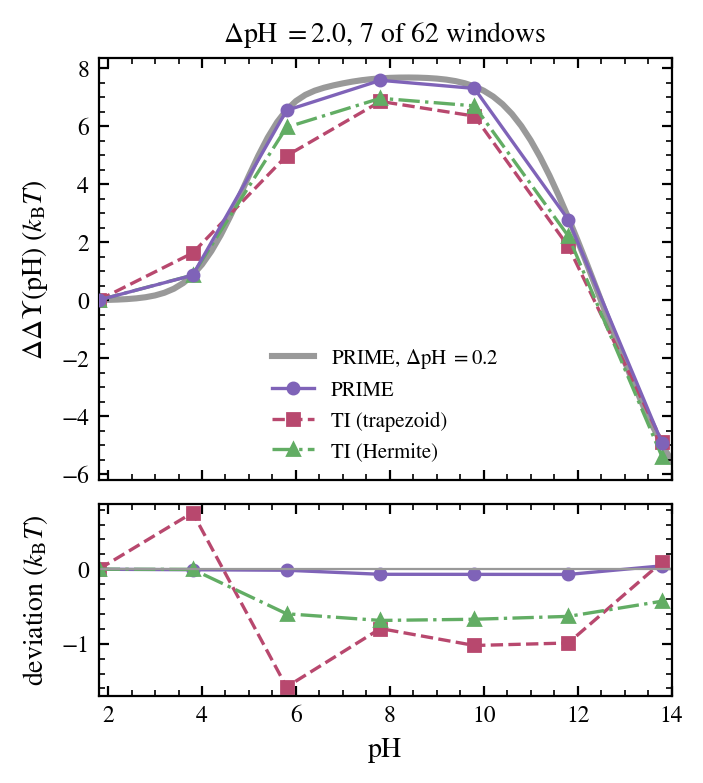

In [20]:
SPACINGS = {1.2: 6, 2.0: 10}                    # spacing: stride on the 0.2 grid
PLOT = 2.0
ref_full = ddY[0]
i78, i138 = int(np.argmin(np.abs(pHs - 7.8))), int(np.argmin(np.abs(pHs - 13.8)))
EST_STYLE = {"PRIME": (C_PRIME, "-", "o"), "trapezoid": (C_TRAP, "--", "s"), "Hermite": (C_HERM, "-.", "^")}
EST_LABEL = {"PRIME": "PRIME", "trapezoid": "TI (trapezoid)", "Hermite": "TI (Hermite)"}

coarse = {}
for dpH, stride in SPACINGS.items():
    idx = np.arange(0, K, stride)
    prof = prime.transition_profiles([H["native"][idx], H["fibril"][idx]], pHs[idx], nmol=(NMOL["native"], NMOL["fibril"]))
    em_herm = (prime.ti_bias_hermite(pHs[idx], mom["fibril"].kappa4[idx]) / NMOL["fibril"]
               - prime.ti_bias_hermite(pHs[idx], mom["native"].kappa4[idx]) / NMOL["native"])
    coarse[dpH] = (idx, prof, ref_full[idx] - ref_full[idx][0], em_herm)

print(f"{'dpH':>4} {'windows':>8} {'estimator':>10} {'ddY(7.8)':>9} {'dev':>7} {'ddY(13.8)':>10} {'dev':>7} {'RMS':>7}")
for e, p in zip(EST, ddY):
    dev = p - ref_full
    print(f"{0.2:>4} {K:>8} {e:>10} {p[i78]:>9.2f} {dev[i78]:>+7.2f} {p[i138]:>10.2f} {dev[i138]:>+7.2f} {np.sqrt(np.mean(dev[1:] ** 2)):>7.3f}")
for dpH, (idx, prof, ref, em_herm) in coarse.items():
    j78, j138 = int(np.argmin(np.abs(pHs[idx] - 7.8))), int(np.argmin(np.abs(pHs[idx] - 13.8)))
    for e, p in zip(EST, prof):
        dev = p - ref
        print(f"{dpH:>4} {len(idx):>8} {e:>10} {p[j78]:>9.2f} {dev[j78]:>+7.2f} {p[j138]:>10.2f} {dev[j138]:>+7.2f} {np.sqrt(np.mean(dev[1:] ** 2)):>7.3f}")
    em_trap = prof[2] - prof[1]                                         # the Euler-Maclaurin estimate of the trapezoid bias is Hermite - trapezoid
    print(f"     Euler-Maclaurin estimates at pH {pHs[idx][j78]:.1f}: trapezoid {em_trap[j78]:+.2f} (actual deviation {(prof[1] - ref)[j78]:+.2f}), "
          f"Hermite {em_herm[j78]:+.3f} (actual {(prof[2] - ref)[j78]:+.2f}); |Hermite estimate| up to {np.abs(em_herm).max():.3f} kT")

idx, prof, ref, _ = coarse[PLOT]
fig, (ax, axd) = plt.subplots(2, 1, figsize=(3.4, 3.8), dpi=200, sharex=True, gridspec_kw={"height_ratios": [2.2, 1.0]},
                              layout="constrained")
ax.plot(pHs, ref_full, color="0.6", lw=2.2, label=r"PRIME, $\Delta$pH $=0.2$", zorder=1)
for e, p in zip(EST, prof):
    col, ls, mk = EST_STYLE[e]
    ax.plot(pHs[idx], p, ls=ls, marker=mk, ms=4, color=col, lw=1.2, label=EST_LABEL[e], zorder=3 if e == "PRIME" else 2)
    axd.plot(pHs[idx], p - ref, ls=ls, marker=mk, ms=4, color=col, lw=1.2)
axd.axhline(0.0, color="0.6", lw=0.8)
ax.set_title(rf"$\Delta$pH $={PLOT}$, {len(idx)} of {K} windows", fontsize=10)
ax.set_ylabel(r"$\Delta\Delta\Upsilon(\mathrm{pH})$ ($k_\mathrm{B}T$)", fontsize=10)
axd.set_ylabel("deviation ($k_\\mathrm{B}T$)", fontsize=10)
axd.set_xlabel("pH", fontsize=10)
for a in (ax, axd):
    a.minorticks_on()
    a.set_xlim(pHs.min(), pHs.max())
    a.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=8.5)
ax.legend(frameon=False, fontsize=7.5, loc="lower center")
fig.savefig(f"{FIG_DIR}/Coarse_grid_comparison.pdf", bbox_inches="tight")
plt.show()

### Distributions at every sixth window, `N_histograms_sparse_native.pdf` (Fig. 4) and `N_histograms_sparse_fibril.pdf` (Fig. S9)

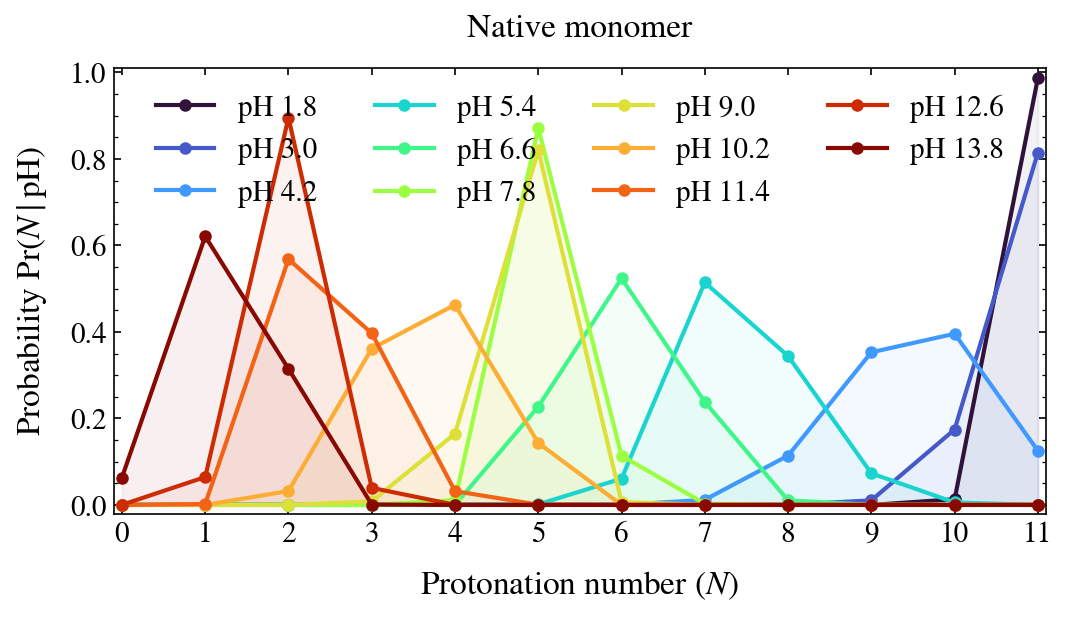

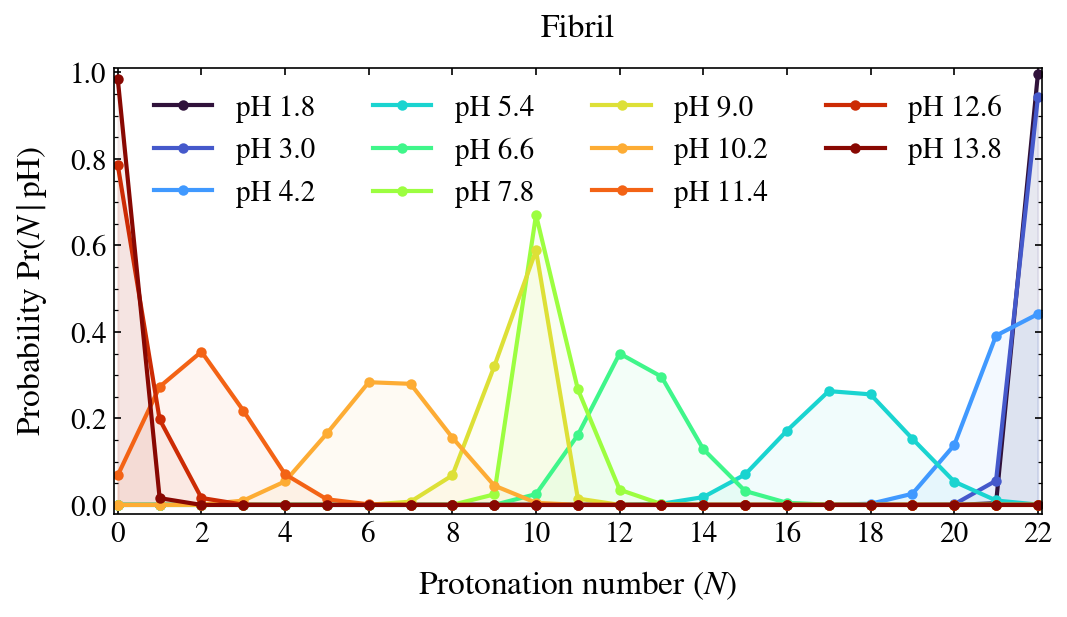

In [21]:
for s, title in zip(STATES, ("Native monomer", "Fibril")):
    N_vals = np.arange(N_SITES[s] + 1)
    fig, ax = plt.subplots(figsize=(7, 4), dpi=150, layout="constrained")
    cmap = plt.get_cmap('turbo')
    for i in range(0, K, 6):                                        # pH 1.8, 3.0, 4.2, ..., a spacing of 1.2
        P = H[s][i] / mom[s].M[i]
        color = cmap((pHs[i] - pHs.min()) / (pHs.max() - pHs.min()))
        ax.plot(N_vals, P, '-o', color=color, linewidth=2.0, markersize=5 if N_SITES[s] <= 12 else 4, label=f"pH {pHs[i]:.1f}")
        ax.fill_between(N_vals, 0, P, color=color, alpha=0.06)
    ax.set_xlabel('Protonation number ($N$)', fontsize=16, labelpad=10)
    ax.set_ylabel(r'Probability $\Pr(N \mid \mathrm{pH})$', fontsize=16, labelpad=10)
    ax.set_title(title, fontsize=16, pad=15)
    ax.set_xticks(N_vals if N_SITES[s] <= 12 else N_vals[::2])
    ax.set_xlim(-0.1, N_SITES[s] + 0.1)
    ax.set_ylim(-0.02, 1.01)
    ax.minorticks_on()
    ax.tick_params(axis='x', which='minor', length=0, width=0)
    ax.tick_params(axis='both', which='both', direction='in', left=True, right=True, bottom=True, top=True, labelsize=14)
    ax.legend(frameon=False, loc='upper center', fontsize=14, ncol=4)
    fig.savefig(f"{FIG_DIR}/N_histograms_sparse_{s}.pdf", bbox_inches='tight')
    plt.show()

## 5. Prediction from one and two pH windows

The two windows of the monomer at the maxima of the protonation variance. A prediction at a pH is reported as determined when no protonation number between the sampled extremes is empty, less than the tolerance of the weight falls on an edge of the sampled range that is not a physical bound, and the connection between the windows survives block resampling (`prime.predict`).

### Free energy from two windows, `Prediction_free_energy_native.pdf` (Fig. 5)

In [22]:
TOLERANCE = 1e-3
PH_REF = pHs[0]
Hn, mn, Sn = H["native"], mom["native"], N_SITES["native"]
pair = [int(k) for k in prime.variance_maxima(Hn)]                 # the two windows at the maxima of the variance
ia, ib = pair
fine = np.linspace(pHs.min(), pHs.max(), 800)
f_ref = dY["native"][0]                                           # 62-window PRIME, relative to pH 1.8
print(f"retained windows pH {pHs[ia]:.1f} and {pHs[ib]:.1f}")


def two_window_free_energy(Hc, pH_eval):
    '''beta [Upsilon(pH_eval) - Upsilon(1.8)] from PRIME on the two histograms Hc, and whether the prediction
    is determined at each pH. None if the two windows share no protonation number.'''
    p = prime.predict(Hc, pHs[pair], pH_eval, n_sites=Sn, tolerance=TOLERANCE)
    if not p["connected"]:
        return None
    return prime.reweight(p["lnc"], pH_eval, pH_ref=PH_REF)[0], p["determined"]


def runs_of(mask):
    idx = np.flatnonzero(mask)
    if len(idx) == 0:
        return []
    return [(s[0], s[-1]) for s in np.split(idx, np.flatnonzero(np.diff(idx) > 1) + 1)]


if two_window_free_energy(Hn[pair], pHs) is None:
    raise RuntimeError(f"the windows at pH {pHs[ia]:.1f} and {pHs[ib]:.1f} share no protonation number")
f_fine, det_fine = two_window_free_energy(Hn[pair], fine)
f_win, det_win = two_window_free_energy(Hn[pair], pHs)
resid = f_win - f_ref

# TI from the same two windows has an integrand only between them, so its lines start at the lower window,
# at the value PRIME predicts there from the same two windows
anchor = f_win[ia]
x_ti = np.linspace(pHs[ia], pHs[ib], 400)
N_ti_trap = np.interp(x_ti, pHs[pair], mn.mean[pair])
N_ti_herm = CubicHermiteSpline(pHs[pair], mn.mean[pair], -np.log(10.0) * mn.var[pair])(x_ti)
integ = lambda N: anchor + np.log(10.0) * np.concatenate([[0.0], np.cumsum(0.5 * (N[1:] + N[:-1]) * np.diff(x_ti))])
f_ti_trap, f_ti_herm = integ(N_ti_trap), integ(N_ti_herm)
ref_ti = np.interp(x_ti, pHs, f_ref)
dev_trap, dev_herm = f_ti_trap - ref_ti, f_ti_herm - ref_ti

# block bootstrap of the two retained windows: the third condition and the band of panel (b)
rng, boots = np.random.default_rng(0), []
for Hb in prime.resample_histograms(h32["native"][pair], rng, n=200):
    out = two_window_free_energy(Hb, pHs)
    if out is not None:
        boots.append(out[0])
robust = len(boots) >= 0.9 * 200
if not robust:
    det_fine[:], det_win[:] = False, False
sig = np.std(boots, axis=0, ddof=1)
band = np.where(det_win, 2 * sig, np.nan)

print(f"{len(boots)} of 200 resamples connected" + ("" if robust else ", the pair is fragile"))
for a, b in runs_of(det_fine):
    print(f"determined from pH {fine[a]:.1f} to {fine[b]:.1f}")
j = np.argmax(np.where(det_win, np.abs(resid), -1))
print(f"predicted - 62 windows where determined: largest {np.abs(resid[j]):.3f} kT at pH {pHs[j]:.1f}, RMS {np.sqrt(np.mean(resid[det_win] ** 2)):.3f}, "
      f"bootstrap sigma up to {sig[det_win].max():.3f} kT; at pH {pHs[ia]:.1f} {resid[ia]:+.3f} kT; the profile rises by "
      f"{f_ref[det_win].max() - f_ref[det_win].min():.1f} kT over the determined windows")
if (~det_win).any():
    print(f"where undetermined (pH {pHs[~det_win].min():.1f} to {pHs[~det_win].max():.1f}): deviation up to {np.abs(resid[~det_win]).max():.2f} kT")
print(f"TI between the windows: at pH {pHs[ib]:.1f} trapezoid {dev_trap[-1]:+.2f}, Hermite {dev_herm[-1]:+.2f} kT from the 62-window value")

retained windows pH 4.6 and 10.2
200 of 200 resamples connected
determined from pH 1.8 to 11.4
predicted - 62 windows where determined: largest 0.276 kT at pH 11.2, RMS 0.186, bootstrap sigma up to 0.139 kT; at pH 4.6 +0.101 kT; the profile rises by 148.7 kT over the determined windows
where undetermined (pH 11.4 to 14.0): deviation up to 1.07 kT
TI between the windows: at pH 10.2 trapezoid +6.13, Hermite +1.82 kT from the 62-window value


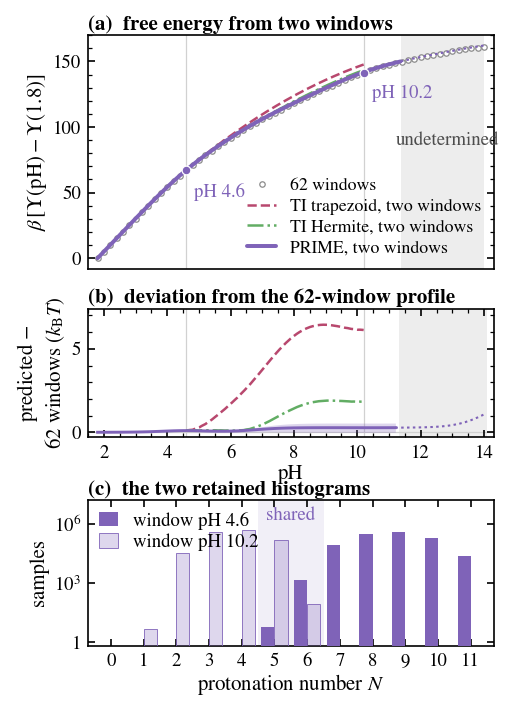

In [31]:
FS = 10
GRAY, GRAY_DK, GRAY_LT, SHADE = "0.55", "0.3", "0.82", "0.93"
C_PRIME_LT = mcolors.to_rgba(C_PRIME, 0.25)
XLIM = (pHs.min() - 0.3, pHs.max() + 0.3)

ratios = [1.0, 0.17, 0.55, 0.27, 0.62]                     # the same white space above every panel title
fig = plt.figure(figsize=(3.4, 4.6), dpi=150)
gs = fig.add_gridspec(5, 1, height_ratios=ratios, hspace=0.0, left=0.19, right=0.985, top=0.97, bottom=0.085)
ax_a, ax_b, ax_c = fig.add_subplot(gs[0]), fig.add_subplot(gs[2]), fig.add_subplot(gs[4])
ax_b.sharex(ax_a)
plt.setp(ax_a.get_xticklabels(), visible=False)

# (a) the free energy
for a, b in runs_of(~det_fine):
    ax_a.axvspan(fine[a], fine[b], color=SHADE, zorder=0, lw=0)
for k in pair:
    ax_a.axvline(pHs[k], color=GRAY_LT, lw=0.6, zorder=1)
ax_a.plot(pHs, f_ref, "o", ms=2.6, mfc="white", mec=GRAY, mew=0.6, ls="none", zorder=2, label="62 windows")
ax_a.plot(x_ti, f_ti_trap, color=C_TRAP, lw=1.2, ls="--", zorder=4, label="TI trapezoid, two windows")
ax_a.plot(x_ti, f_ti_herm, color=C_HERM, lw=1.2, ls="-.", zorder=4, label="TI Hermite, two windows")
ax_a.plot(fine, np.where(det_fine, f_fine, np.nan), color=C_PRIME, lw=1.9, solid_capstyle="round", zorder=5, label="PRIME, two windows")
ax_a.plot(fine, np.where(~det_fine, f_fine, np.nan), color=C_PRIME, lw=1.0, ls=(0, (1.2, 1.6)), zorder=5)
ax_a.plot(pHs[pair], f_ref[pair], "o", ms=4.2, mfc=C_PRIME, mec="white", mew=0.6, ls="none", zorder=6)
for k in pair:
    ax_a.text(pHs[k] + 0.25, f_ref[k] - 0.06 * f_ref.max(), f"pH {pHs[k]:.1f}", color=C_PRIME, fontsize=FS - 1, ha="left", va="top")
if (~det_fine).any():
    a, b = runs_of(~det_fine)[-1]
    ax_a.text(0.5 * (fine[a] + (XLIM[1] if b == len(fine) - 1 else fine[b])), 0.55, "undetermined" if robust else "fragile",
              color=GRAY_DK, fontsize=FS - 1, ha="center", va="center", transform=ax_a.get_xaxis_transform())
ax_a.set_xlim(*XLIM)
ax_a.set_ylabel(r"$\beta\,[\Upsilon(\mathrm{pH}) - \Upsilon(1.8)]$", fontsize=FS, labelpad=2)
ax_a.set_title("(a)  free energy from two windows", loc="left", fontsize=FS, fontweight="bold", pad=2.5)
ax_a.legend(loc="lower right", frameon=False, fontsize=FS - 1.5, handlelength=1.6, borderaxespad=0.3, labelspacing=0.25)
ax_a.minorticks_on()
ax_a.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=FS - 1)
ax_a.tick_params(axis="x", which="both", length=0)

# (b) the deviation from the 62-window profile
for a, b in runs_of(~det_win):
    ax_b.axvspan(pHs[a] - 0.1, pHs[b] + 0.1, color=SHADE, zorder=0, lw=0)
ax_b.axhline(0, color=GRAY_LT, lw=0.6, zorder=1)
for k in pair:
    ax_b.axvline(pHs[k], color=GRAY_LT, lw=0.6, zorder=1)
ax_b.fill_between(pHs, resid - band, resid + band, color=C_PRIME_LT, lw=0, zorder=2)
ax_b.plot(pHs, np.where(det_win, resid, np.nan), color=C_PRIME, lw=1.4, zorder=5)
for a, b in runs_of(~det_win):                                   # dotted where undetermined, joined to the solid part
    a0, b0 = max(a - 1, 0), min(b + 1, K - 1)
    ax_b.plot(pHs[a0:b0 + 1], resid[a0:b0 + 1], color=C_PRIME, lw=1.0, ls=(0, (1.2, 1.6)), zorder=5)
ax_b.plot(x_ti, dev_trap, color=C_TRAP, lw=1.2, ls="--", zorder=4)
ax_b.plot(x_ti, dev_herm, color=C_HERM, lw=1.2, ls="-.", zorder=4)
vals = np.concatenate([resid, (resid - band)[det_win], (resid + band)[det_win], dev_trap, dev_herm])
ax_b.set_ylim(min(-0.3, 1.15 * vals.min()), max(0.3, 1.15 * vals.max()))
ax_b.set_xlim(*XLIM)
ax_b.set_ylabel("predicted $-$\n62 windows ($k_\\mathrm{B}T$)", fontsize=FS, labelpad=2)
ax_b.set_title("(b)  deviation from the 62-window profile", loc="left", fontsize=FS, fontweight="bold", pad=2.5)
ax_b.set_xlabel("pH", fontsize=FS, labelpad=1.0)
ax_b.set_xticks(np.arange(2, 15, 2))
ax_b.minorticks_on()
ax_b.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=FS - 1)

# (c) the two retained histograms
Nax = np.arange(Sn + 1)
c1, c2 = Hn[ia].astype(float), Hn[ib].astype(float)
shared = (c1 > 0) & (c2 > 0)
ax_c.bar(Nax - 0.2, np.where(c1 > 0, c1, np.nan), width=0.4, bottom=0.7, color=C_PRIME, lw=0, zorder=3, label=f"window pH {pHs[ia]:.1f}")
ax_c.bar(Nax + 0.2, np.where(c2 > 0, c2, np.nan), width=0.4, bottom=0.7, color=C_PRIME_LT, edgecolor=C_PRIME, lw=0.4, zorder=3,
         label=f"window pH {pHs[ib]:.1f}")
if shared.any():
    lo_s, hi_s = Nax[shared].min() - 0.5, Nax[shared].max() + 0.5
    ax_c.axvspan(lo_s, hi_s, color=C_PRIME, alpha=0.10, lw=0, zorder=0)
    ax_c.text(0.5 * (lo_s + hi_s), 1e6, "shared", color=C_PRIME, fontsize=FS - 1, ha="center", va="bottom")
ax_c.set_yscale("log")
ax_c.set_ylim(0.7, 1.5e7)
ax_c.set_yticks([1, 1e3, 1e6])
ax_c.set_yticklabels(["1", "10$^3$", "10$^6$"])
ax_c.set_xlim(-0.7, Sn + 0.7)
ax_c.set_xticks(Nax)
ax_c.set_xlabel("protonation number $N$", fontsize=FS, labelpad=1.0)
ax_c.set_ylabel("samples", fontsize=FS, labelpad=2)
ax_c.set_title("(c)  the two retained histograms", loc="left", fontsize=FS, fontweight="bold", pad=2.5)
ax_c.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=FS - 1)
ax_c.tick_params(axis="y", which="minor", length=0)
ax_c.legend(loc="upper left", frameon=False, fontsize=FS - 1, handlelength=1.0, handleheight=0.8, borderaxespad=0.2, labelspacing=0.2)

fig.savefig(f"{FIG_DIR}/Prediction_free_energy_native.pdf", bbox_inches="tight")
plt.show()

### Titration curve from one and from two windows, `Prediction_native.pdf` (Fig. S10)

window pH 4.6 alone: determined from pH 1.8 to 5.3
window pH 10.2 alone: determined from pH 9.7 to 11.4
two windows: determined from pH 1.8 to 11.4
100 of 100 resamples connected
deviation from the simulated curve: PRIME up to 0.07 proton where determined, 0.47 at pH 14; TI between the windows up to 1.02 (trapezoid) and 0.46 (Hermite)


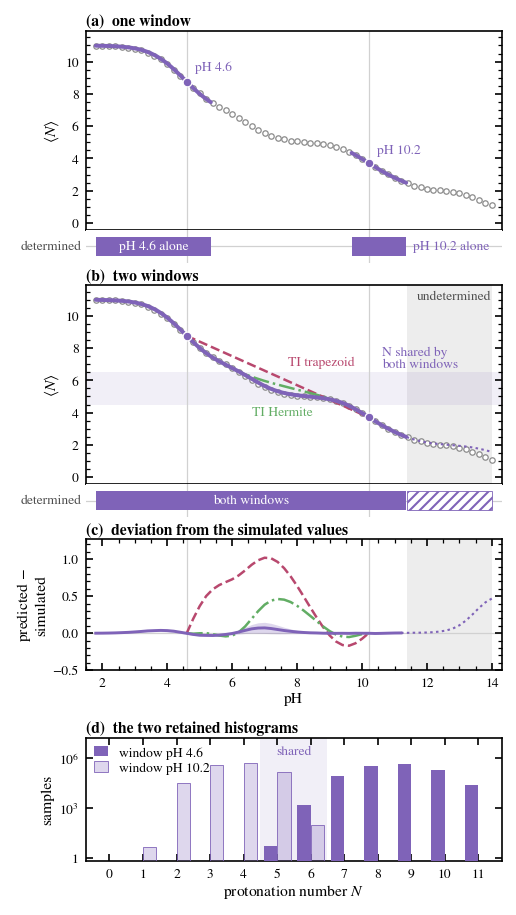

In [24]:
def window_curve(keep, pH_eval, tolerance=TOLERANCE):
    '''<N>(pH_eval) from PRIME on the windows `keep` (one or two) and whether the prediction is determined.'''
    p = prime.predict(Hn[keep], pHs[keep], pH_eval, n_sites=Sn, tolerance=tolerance)
    return (p["mean"], p["determined"]) if p["connected"] else None


one = {k: window_curve([k], fine) for k in pair}                    # each window alone
y_both, det_both = window_curve(pair, fine)
pred_win = prime.predict(Hn[pair], pHs[pair], pHs, n_sites=Sn, h_blk=h32["native"][pair], tolerance=TOLERANCE, n_boot=100)
res_ap = pred_win["mean"] - mn.mean                                 # predicted - simulated at every window
sig_ap = pred_win["sigma"]                                          # block-bootstrap standard error of the prediction, as in Fig. 5(b)
held = np.setdiff1d(np.arange(K), pair)
fragile = pred_win["fragile"]

for k in pair:
    for a, b in runs_of(one[k][1]):
        print(f"window pH {pHs[k]:.1f} alone: determined from pH {fine[a]:.1f} to {fine[b]:.1f}")
for a, b in runs_of(det_both):
    print(f"two windows: determined from pH {fine[a]:.1f} to {fine[b]:.1f}")
det_w = np.isfinite(sig_ap)
print(f"{pred_win['n_boot_ok']} of 100 resamples connected" + (", fragile" if fragile else ""))
held_det = det_w & np.isin(np.arange(K), held)
dev_trap_N = np.interp(pHs[ia:ib + 1], x_ti, N_ti_trap) - mn.mean[ia:ib + 1]
dev_herm_N = np.interp(pHs[ia:ib + 1], x_ti, N_ti_herm) - mn.mean[ia:ib + 1]
print(f"deviation from the simulated curve: PRIME up to {np.abs(res_ap[held_det]).max():.2f} proton where determined, "
      f"{np.abs(res_ap[-1]):.2f} at pH 14; TI between the windows up to {np.abs(dev_trap_N).max():.2f} (trapezoid) and "
      f"{np.abs(dev_herm_N).max():.2f} (Hermite)")

# ---- figure ----
YLIM = (-0.4, Sn + 0.9)
N_sim = mn.mean


def base_panel(ax, label):
    ax.plot(pHs, N_sim, "o", ms=2.6, mfc="white", mec=GRAY, mew=0.6, ls="none", zorder=2)
    for k in pair:
        ax.axvline(pHs[k], color=GRAY_LT, lw=0.6, zorder=1)
    ax.set_xlim(*XLIM)
    ax.set_ylim(*YLIM)
    ax.set_yticks(np.arange(0, Sn + 1, 2))
    ax.set_ylabel(r"$\langle N\rangle$", fontsize=FS, labelpad=2)
    ax.set_title(label, loc="left", fontsize=FS, fontweight="bold", pad=2.5)
    ax.minorticks_on()
    ax.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=FS - 1)
    ax.tick_params(axis="x", which="both", length=0)


def strip(ax):
    ax.set_ylim(0, 1)
    ax.set_yticks([])
    ax.tick_params(axis="x", which="both", length=0)
    for s_ in ("left", "right", "top", "bottom"):
        ax.spines[s_].set_visible(False)
    ax.axhline(0.5, color=GRAY_LT, lw=0.6, zorder=1)
    for k in pair:
        ax.axvline(pHs[k], color=GRAY_LT, lw=0.6, zorder=1)
    ax.text(XLIM[0] - 0.15, 0.5, "determined", fontsize=FS - 1, color=GRAY_DK, ha="right", va="center", clip_on=False)


def bar(ax, lo, hi, hatch=None):
    ax.add_patch(Rectangle((lo, 0.22), hi - lo, 0.56, facecolor="white" if hatch else C_PRIME,
                           edgecolor=C_PRIME if hatch else "none", hatch=hatch, lw=0.4 if hatch else 0, zorder=3))


def bar_label(ax, lo, hi, text):
    if hi - lo >= 2.2:
        ax.text(0.5 * (lo + hi), 0.5, text, color="white", fontsize=FS - 1, ha="center", va="center", zorder=4)
    else:
        ax.text(hi + 0.2, 0.5, text, color=C_PRIME, fontsize=FS - 1, ha="left", va="center", zorder=4)


fig = plt.figure(figsize=(3.4, 6.1), dpi=150)
gs = fig.add_gridspec(9, 1, height_ratios=[1.0, 0.17, 0.11, 1.0, 0.17, 0.11, 0.66, 0.34, 0.62], hspace=0.0,
                      left=0.17, right=0.985, top=0.972, bottom=0.065)
ax_a, st_a = fig.add_subplot(gs[0]), fig.add_subplot(gs[1])
ax_b, st_b = fig.add_subplot(gs[3]), fig.add_subplot(gs[4])
ax_c, ax_d = fig.add_subplot(gs[6]), fig.add_subplot(gs[8])
for a_ in (st_a, ax_b, st_b, ax_c):
    a_.sharex(ax_a)
for a_ in (ax_a, st_a, ax_b, st_b):
    plt.setp(a_.get_xticklabels(), visible=False)

# (a) one window
base_panel(ax_a, "(a)  one window")
for k in pair:
    y, d = one[k]
    ax_a.plot(fine, np.where(d, y, np.nan), color=C_PRIME, lw=1.9, solid_capstyle="round", zorder=5)
ax_a.plot(pHs[pair], N_sim[pair], "o", ms=4.2, mfc=C_PRIME, mec="white", mew=0.6, ls="none", zorder=6)
ax_a.text(pHs[ia] + 0.25, N_sim[ia] + 0.05 * Sn, f"pH {pHs[ia]:.1f}", color=C_PRIME, fontsize=FS - 1, ha="left", va="bottom")
ax_a.text(pHs[ib] + 0.25, N_sim[ib] + 0.04 * Sn, f"pH {pHs[ib]:.1f}", color=C_PRIME, fontsize=FS - 1, ha="left", va="bottom")
strip(st_a)
for k in pair:
    for a, b in runs_of(one[k][1]):
        bar(st_a, fine[a], fine[b])
a0, b0 = runs_of(one[ia][1])[0]
bar_label(st_a, fine[a0], fine[b0], f"pH {pHs[ia]:.1f} alone")
a1, b1 = runs_of(one[ib][1])[-1]
bar_label(st_a, fine[a1], fine[b1], f"pH {pHs[ib]:.1f} alone")

# (b) two windows
base_panel(ax_b, "(b)  two windows")
for a, b in runs_of(~det_both):
    ax_b.axvspan(fine[a], fine[b], color=SHADE, zorder=0, lw=0)
if shared.any():
    ax_b.axhspan(lo_s, hi_s, color=C_PRIME, alpha=0.10, lw=0, zorder=0)
    ax_b.text(pHs[ib] + 0.4, hi_s + 0.01 * Sn, "N shared by\nboth windows", color=C_PRIME, fontsize=FS - 1, ha="left", va="bottom", linespacing=1.05)
ax_b.plot(x_ti, N_ti_trap, color=C_TRAP, lw=1.2, ls="--", zorder=4)
ax_b.plot(x_ti, N_ti_herm, color=C_HERM, lw=1.2, ls="-.", zorder=4)
if fragile:
    ax_b.plot(fine, y_both, color=C_PRIME, lw=1.0, ls=(0, (1.2, 1.6)), zorder=5)
else:
    ax_b.plot(fine, np.where(det_both, y_both, np.nan), color=C_PRIME, lw=1.9, solid_capstyle="round", zorder=5)
    ax_b.plot(fine, np.where(~det_both, y_both, np.nan), color=C_PRIME, lw=1.0, ls=(0, (1.2, 1.6)), zorder=5)
ax_b.plot(pHs[pair], N_sim[pair], "o", ms=4.2, mfc=C_PRIME, mec="white", mew=0.6, ls="none", zorder=6)
j = len(x_ti) // 2
ax_b.text(x_ti[j] + 0.3, N_ti_trap[j] + 0.05 * Sn, "TI trapezoid", color=C_TRAP, fontsize=FS - 1, ha="left", va="bottom")
j = int(np.argmax(N_ti_herm - np.interp(x_ti, fine, y_both)))
ax_b.text(x_ti[j], np.interp(x_ti[j], fine, y_both) - 0.08 * Sn, "TI Hermite", color=C_HERM, fontsize=FS - 1, ha="center", va="top")
if (~det_both).any():
    a, b = runs_of(~det_both)[-1]
    ax_b.text(0.5 * (fine[a] + XLIM[1]), YLIM[1] - 0.03 * Sn, "undetermined", color=GRAY_DK, fontsize=FS - 1, ha="center", va="top")
strip(st_b)
for a, b in runs_of(det_both):
    bar(st_b, fine[a], fine[b], hatch="/////" if fragile else None)
for a, b in runs_of(~det_both):
    bar(st_b, fine[a], fine[b], hatch="/////")
a0, b0 = runs_of(det_both)[0]
bar_label(st_b, fine[a0], fine[b0], "both windows, fragile" if fragile else "both windows")

# (c) the deviation at the windows
for a, b in runs_of(~det_both):
    ax_c.axvspan(fine[a], fine[b], color=SHADE, zorder=0, lw=0)
ax_c.axhline(0, color=GRAY_LT, lw=0.6, zorder=1)
for k in pair:
    ax_c.axvline(pHs[k], color=GRAY_LT, lw=0.6, zorder=1)
band_N = np.where(det_w, 2 * sig_ap, np.nan)
ax_c.fill_between(pHs, res_ap - band_N, res_ap + band_N, color=C_PRIME_LT, lw=0, zorder=2)
ax_c.plot(pHs, np.where(det_w, res_ap, np.nan), color=C_PRIME, lw=1.4, zorder=5)
if (~det_w).any():
    j0 = max(np.flatnonzero(~det_w)[0] - 1, 0)
    ax_c.plot(pHs[j0:], res_ap[j0:], color=C_PRIME, lw=1.0, ls=(0, (1.2, 1.6)), zorder=5)
ax_c.plot(pHs[ia:ib + 1], dev_trap_N, color=C_TRAP, lw=1.2, ls="--", zorder=4)
ax_c.plot(pHs[ia:ib + 1], dev_herm_N, color=C_HERM, lw=1.2, ls="-.", zorder=4)
lo = min(-0.5, np.nanmin(np.concatenate([dev_trap_N, dev_herm_N, res_ap - band_N])) - 0.1)
hi = max(np.nanmax(np.concatenate([dev_trap_N, dev_herm_N, res_ap + band_N])) + 0.25, 0.6)
ax_c.set_xlim(*XLIM)
ax_c.set_ylim(lo, hi)
ax_c.set_ylabel("predicted $-$\nsimulated", fontsize=FS, labelpad=2)
ax_c.set_xlabel("pH", fontsize=FS, labelpad=1.0)
ax_c.set_xticks(np.arange(2, 15, 2))
ax_c.set_title("(c)  deviation from the simulated values", loc="left", fontsize=FS, fontweight="bold", pad=2.5)
ax_c.minorticks_on()
ax_c.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=FS - 1)

# (d) the two histograms
ax_d.bar(Nax - 0.2, np.where(c1 > 0, c1, np.nan), width=0.4, bottom=0.7, color=C_PRIME, lw=0, zorder=3, label=f"window pH {pHs[ia]:.1f}")
ax_d.bar(Nax + 0.2, np.where(c2 > 0, c2, np.nan), width=0.4, bottom=0.7, color=C_PRIME_LT, edgecolor=C_PRIME, lw=0.4, zorder=3,
         label=f"window pH {pHs[ib]:.1f}")
if shared.any():
    ax_d.axvspan(lo_s, hi_s, color=C_PRIME, alpha=0.10, lw=0, zorder=0)
    ax_d.text(0.5 * (lo_s + hi_s), 1e6, "shared", color=C_PRIME, fontsize=FS - 1, ha="center", va="bottom")
ax_d.set_yscale("log")
ax_d.set_ylim(0.7, 1.5e7)
ax_d.set_yticks([1, 1e3, 1e6])
ax_d.set_yticklabels(["1", "10$^3$", "10$^6$"])
ax_d.set_xlim(-0.7, Sn + 0.7)
ax_d.set_xticks(Nax)
ax_d.set_xlabel("protonation number $N$", fontsize=FS, labelpad=1.0)
ax_d.set_ylabel("samples", fontsize=FS, labelpad=2)
ax_d.set_title("(d)  the two retained histograms", loc="left", fontsize=FS, fontweight="bold", pad=2.5)
ax_d.tick_params(axis="both", which="both", direction="in", top=True, right=True, labelsize=FS - 1)
ax_d.tick_params(axis="y", which="minor", length=0)
ax_d.legend(loc="upper left", frameon=False, fontsize=FS - 1, handlelength=1.0, handleheight=0.8, borderaxespad=0.2, labelspacing=0.2)

fig.savefig(f"{FIG_DIR}/Prediction_native.pdf", bbox_inches="tight")
plt.show()

### Worked example (Table S5), the tolerance, and the pair of the fibril

For a set of pH values, the weight that lands on an edge of the sampled range that is not a physical bound, for each window alone and for the two together, with the predicted and the simulated average. Entries above the tolerance are in parentheses.

In [25]:
PH_ROWS = (2.0, 4.0, 5.0, 5.2, 5.4, 6.0, 7.0, 8.0, 9.0, 9.6, 10.0, 11.0, 11.4, 11.6, 12.0, 13.0, 14.0)


def edge_weight(keep, pH):
    '''Largest weight on an edge of the sampled range that is not a physical bound, and <N>, at one pH.'''
    lnc = prime.predict(Hn[keep], pHs[keep], [pH], n_sites=Sn)["lnc"]
    w_lo, w_hi, N_lo, N_hi = prime.edge_weights(lnc, [pH])
    f = max(w_lo[0] if N_lo > 0 else 0.0, w_hi[0] if N_hi < Sn else 0.0)
    return f, prime.reweight(lnc, [pH])[1][0]


def fmt(f):
    if f < 1e-6:
        return "$<10^{-6}$"
    if f >= 0.01:
        return f"{f:.2f}"
    m, e = f"{f:.1e}".split("e")
    return f"${m}\\times10^{{{int(e)}}}$"


cases = {f"{pHs[ia]:.1f} alone": [ia], f"{pHs[ib]:.1f} alone": [ib], "both": pair}
print(r"\hline")
print("pH & $\\langle N\\rangle$ simulated & $\\langle N\\rangle$ from both & " + " & ".join(f"pH {c}" if "alone" in c else c for c in cases) + r" \\")
print(r"\hline")
for pH in PH_ROWS:
    k = int(np.argmin(np.abs(pHs - pH)))
    cells_, N_both = [], np.nan
    for name, keep in cases.items():
        f, Nav = edge_weight(keep, pH)
        cells_.append(fmt(f) if f < TOLERANCE else "(" + fmt(f) + ")")
        if name == "both":
            N_both = Nav
    print(f"{pH:.1f} & {mn.mean[k]:.2f} & {N_both:.2f} & " + " & ".join(cells_) + r" \\")
print(r"\hline")

# the tolerance is a chosen number: the determined range of the pair and of the lower window alone for three values
for tol in (1e-2, 1e-3, 1e-4):
    both = runs_of(window_curve(pair, fine, tol)[1])[0]
    lower = runs_of(window_curve([ia], fine, tol)[1])[0]
    print(f"tolerance {tol:.0e}: both windows determined from pH {fine[both[0]]:.1f} to {fine[both[1]]:.1f}, "
          f"pH {pHs[ia]:.1f} alone from {fine[lower[0]]:.1f} to {fine[lower[1]]:.1f}")

# the two windows of the fibril at its variance maxima share a single protonation number through few records
Hf, Sf = H["fibril"], N_SITES["fibril"]
pf = [int(k) for k in prime.variance_maxima(Hf)]
shared_f = np.flatnonzero((Hf[pf[0]] > 0) & (Hf[pf[1]] > 0))
pp = prime.predict(Hf[pf], pHs[pf], pHs, n_sites=Sf, h_blk=h32["fibril"][pf], tolerance=TOLERANCE, n_boot=100)
held_f = np.setdiff1d(np.arange(K), pf)
print(f"fibril, windows pH {pHs[pf[0]]:.1f} and {pHs[pf[1]]:.1f}: shared N = {shared_f}, records {Hf[pf[0]][shared_f]} and {Hf[pf[1]][shared_f]}")
if pp["connected"]:
    print(f"   {pp['n_boot_ok']} of 100 resamples connected, fragile = {pp['fragile']}; the prediction deviates by up to "
          f"{np.abs(pp['mean'] - mom['fibril'].mean)[held_f].max():.2f} proton at the withheld windows")
else:
    print("   the two windows share no protonation number")

\hline
pH & $\langle N\rangle$ simulated & $\langle N\rangle$ from both & pH 4.6 alone & pH 10.2 alone & both \\
\hline
2.0 & 10.98 & 10.98 & $<10^{-6}$ & (1.00) & $<10^{-6}$ \\
4.0 & 9.85 & 9.88 & $<10^{-6}$ & (1.00) & $<10^{-6}$ \\
5.0 & 8.03 & 8.00 & $1.1\times10^{-4}$ & (0.99) & $<10^{-6}$ \\
5.2 & 7.71 & 7.69 & $4.1\times10^{-4}$ & (0.98) & $<10^{-6}$ \\
5.4 & 7.44 & 7.41 & ($1.3\times10^{-3}$) & (0.98) & $<10^{-6}$ \\
6.0 & 6.77 & 6.77 & (0.02) & (0.91) & $<10^{-6}$ \\
7.0 & 5.58 & 5.65 & (0.41) & (0.50) & $<10^{-6}$ \\
8.0 & 5.06 & 5.08 & (0.89) & (0.09) & $<10^{-6}$ \\
9.0 & 4.83 & 4.83 & (0.99) & ($8.2\times10^{-3}$) & $<10^{-6}$ \\
9.6 & 4.43 & 4.42 & (1.00) & ($1.3\times10^{-3}$) & $<10^{-6}$ \\
10.0 & 3.97 & 3.97 & (1.00) & $2.5\times10^{-4}$ & $1.1\times10^{-6}$ \\
11.0 & 2.81 & 2.81 & (1.00) & $2.5\times10^{-4}$ & $2.5\times10^{-4}$ \\
11.4 & 2.46 & 2.47 & (1.00) & ($1.1\times10^{-3}$) & ($1.1\times10^{-3}$) \\
11.6 & 2.33 & 2.33 & (1.00) & ($2.1\times10^{-3}$) & ($2.1\ti

## 6. Consistency of the pH windows

The stepwise p$K_N$ of every step $N-1 \rightarrow N$ measured in every window that samples both of its protonation numbers, against the pH of the window. If the windows sample the same ensemble, every step is flat within its error bars. $\tau$ is the scatter between the windows beyond their statistical errors.

### The test for both states, `Consistency_strips.pdf` (Fig. 6) and `Consistency_strips_fibril.pdf` (Fig. S11)

native
   step  windows           pKa mean   PRIME  chi2/dof   p(Q)     tau
  0->1          8      14.843 +- 0.013  14.769      2.62   0.01   0.048   <-- inconsistent
  1->2         16      13.647 +- 0.003  13.600     91.34   0.00   0.123   <-- inconsistent
  2->3         24      11.245 +- 0.000  11.247      4.18   0.00   0.003
  3->4         22      10.307 +- 0.001  10.308      1.60   0.04   0.002
  4->5         24       9.694 +- 0.001   9.693      0.86   0.65   0.000
  5->6         25       6.938 +- 0.001   6.935     81.28   0.00   0.026   <-- inconsistent
  6->7         20       6.283 +- 0.000   6.290    279.20   0.00   0.038   <-- inconsistent
  7->8         19       5.221 +- 0.001   5.228     20.50   0.00   0.018   <-- inconsistent
  8->9         18       4.705 +- 0.001   4.709     13.72   0.00   0.020   <-- inconsistent
  9->10        19       4.249 +- 0.001   4.250     14.69   0.00   0.024   <-- inconsistent
 10->11        18       3.687 +- 0.002   3.679      4.94   0.00   0.019

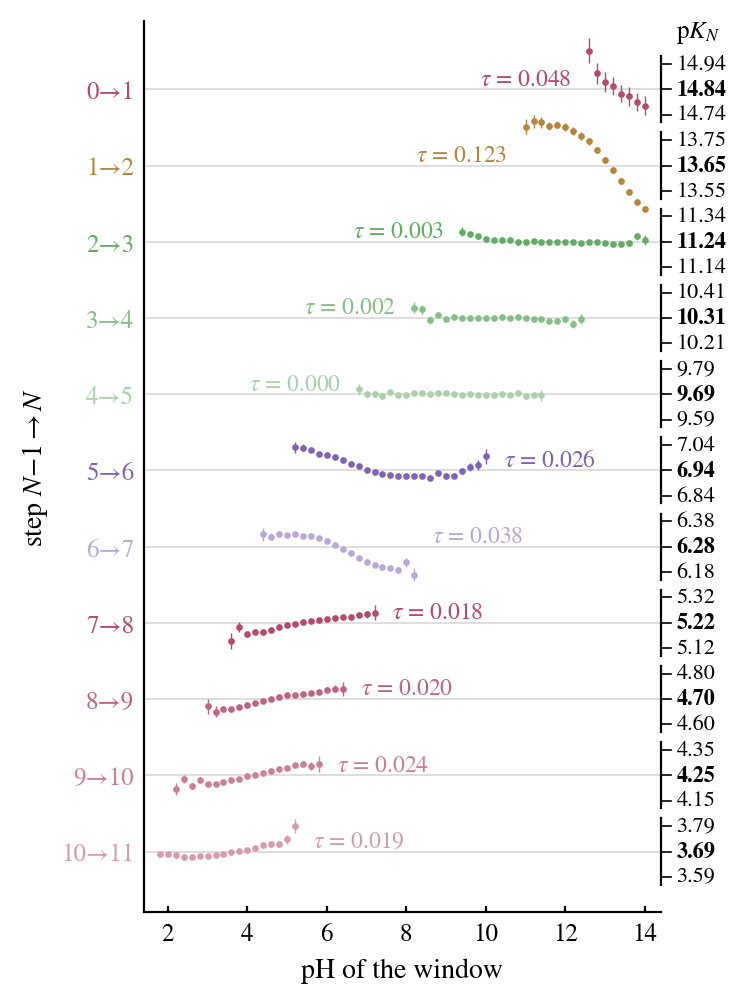

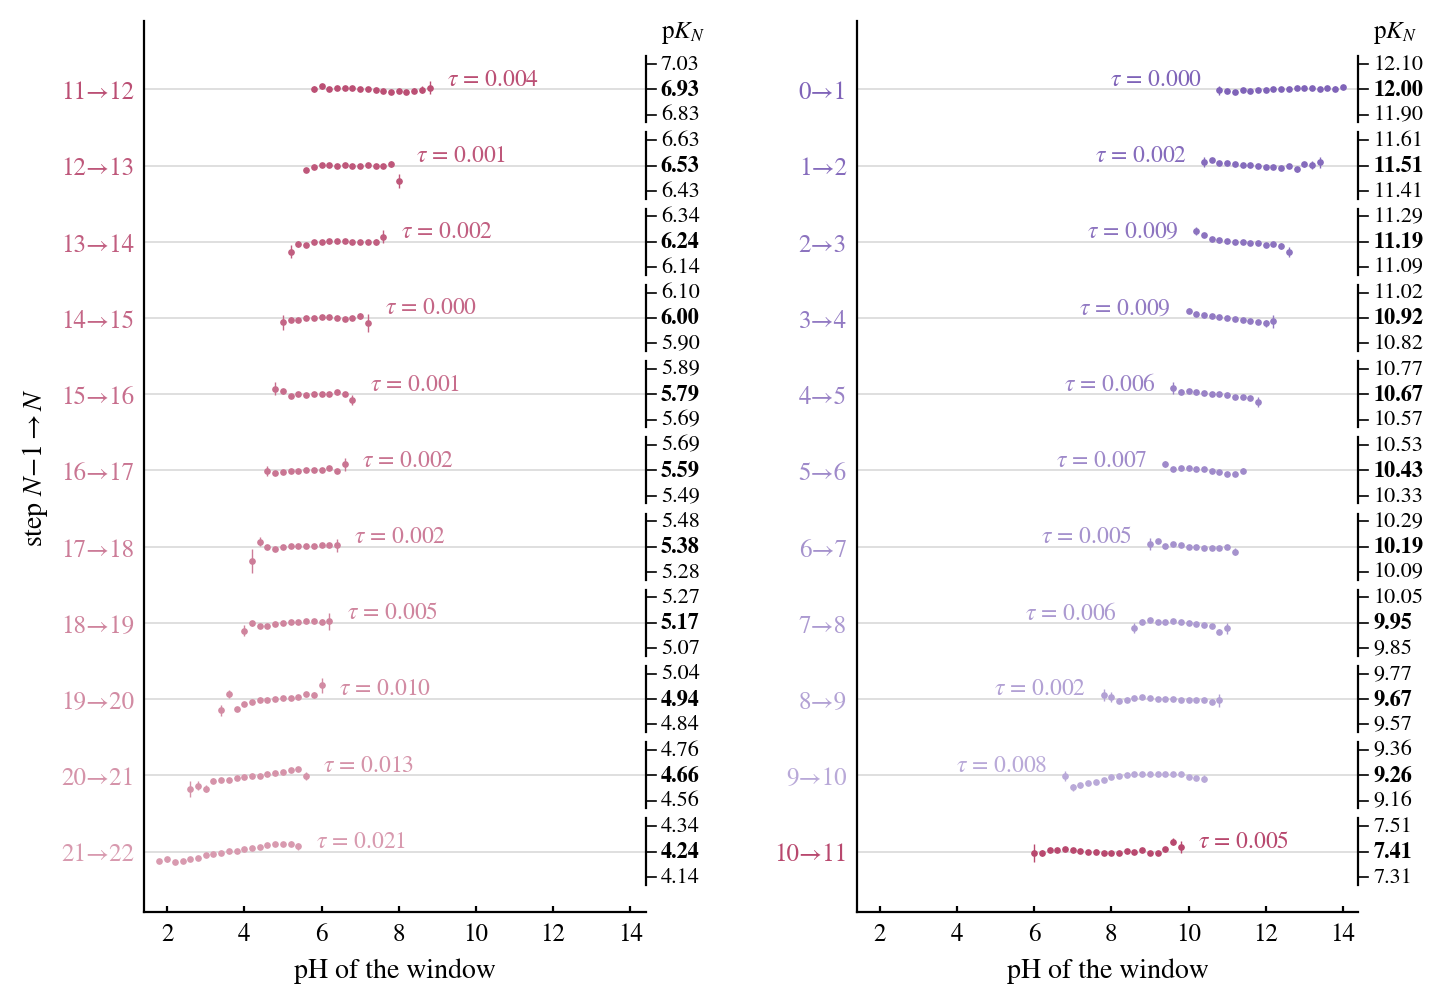

In [30]:
cons = {}
for s in STATES:
    cons[s] = prime.consistency_test(H[s], pHs, h32[s], n_boot=400, min_count=200, max_se=0.1)
    c = cons[s]
    print(f"{s}\n" + prime.format_consistency(c))
    valid = c["n_windows"] >= 2
    d = np.abs(c["pK_prime"] - c["pK_mean"])[valid]
    print(f"PRIME against the weighted mean of the windows: within {np.sort(d)[-3]:.3f} pK units for all but two steps, "
          f"{d.max():.3f} at most; largest tau {np.nanmax(c['tau']):.3f}, {int((c['tau'][valid] > 0.01).sum())} of {valid.sum()} steps above 0.01\n")


def step_colors(c, gap=1.0):
    '''One color per residue group, the steps whose pK_N lie within `gap` of each other, lightened up the group.'''
    valid = np.flatnonzero(c["n_windows"] >= 2)
    order = valid[np.argsort(c["pK_mean"][valid])]
    groups, cur = [], [order[0]]
    for a, b in zip(order[:-1], order[1:]):
        if c["pK_mean"][b] - c["pK_mean"][a] > gap:
            groups.append(cur)
            cur = []
        cur.append(b)
    groups.append(cur)
    base_cols = [COLORS[2], COLORS[0], COLORS[1], COLORS[3]] * 3
    cols = {}
    for gi, g in enumerate(groups):
        base = np.array(mcolors.to_rgb(base_cols[gi]))
        for j in g:
            frac = 0.0 if len(g) == 1 else 0.45 * sorted(g).index(j) / (len(g) - 1)
            cols[int(j)] = tuple(base + (1.0 - base) * frac)
    return cols


def strips_input(c):
    return dict(dev=c["pK"] - c["pK_mean"][None, :], se=c["se"], usable=c["usable"], pK_mean=c["pK_mean"], tau=c["tau"],
                steps=c["steps"], rows=sorted([int(j) for j in np.flatnonzero(c["n_windows"] >= 2)], key=lambda j: c["pK_mean"][j]),
                cols=step_colors(c))


FS, OFF = 10, 0.30                                              # font size, vertical offset between steps in pK units


def draw_strips(ax, R, rows, sets, line_text):
    '''One strip per step of `rows`, bottom first. sets: (values relative to the zero line, errors, mask, hollow),
    arrays of shape (K, n_steps), drawn on every strip; line_text(j) is written on the zero line.'''
    row_of = {j: i for i, j in enumerate(rows)}
    x_mid = 0.5 * (pHs[0] + pHs[-1])
    for j in rows:
        y0, c = row_of[j] * OFF, R["cols"][j]
        ax.axhline(y0, color="0.85", lw=0.6, zorder=0)
        xs = []
        for vals, ses, mask, hollow in sets:
            m = mask[:, j]
            ax.errorbar(pHs[m], vals[m, j] + y0, yerr=ses[m, j], fmt="o", ms=1.9, mfc="white" if hollow else c,
                        mec=c, mew=0.5, ecolor=c, elinewidth=0.5, capsize=0, zorder=3 if hollow else 2)
            xs.append(pHs[m])
        xs = np.concatenate(xs)
        right = xs.mean() < x_mid                                  # the empty half of the strip
        ax.text(xs.max() + 0.45 if right else xs.min() - 0.45, y0 + 0.04, line_text(j), fontsize=FS - 1.5,
                ha="left" if right else "right", va="center", color=c)
    ax.set_yticks([row_of[j] * OFF for j in rows])
    ax.set_yticklabels([f"{R['steps'][j] - 1}→{R['steps'][j]}" for j in rows], fontsize=FS - 1)
    for lab, j in zip(ax.get_yticklabels(), rows):
        lab.set_color(R["cols"][j])
    ax.set_ylabel("step $N{-}1 \\rightarrow N$", fontsize=FS)
    ax.set_ylim(-OFF * 0.8, (len(rows) - 1) * OFF + OFF * 0.9)
    ax.tick_params(axis="y", which="major", length=0)
    tr = ax.get_yaxis_transform()                                  # the pK_N ladder on the right, one segment per strip
    for j in rows:
        y0 = row_of[j] * OFF
        ax.plot([1, 1], [y0 - 0.13, y0 + 0.13], "-", color="k", lw=0.8, transform=tr, clip_on=False, zorder=5)
        for dy in (-0.1, 0.0, 0.1):
            ax.plot([1, 1.02], [y0 + dy, y0 + dy], "-", color="k", lw=0.6, transform=tr, clip_on=False, zorder=5)
            ax.text(1.03, y0 + dy, f"{R['pK_mean'][j] + dy:.2f}", fontsize=FS - 2, ha="left", va="center",
                    transform=tr, fontweight="bold" if dy == 0 else "normal")
    ax.text(1.03, (len(rows) - 1) * OFF + OFF * 0.75, "p$K_N$", fontsize=FS - 1, ha="left", va="center", transform=tr)
    ax.set_xlim(pHs[0] - 0.4, pHs[-1] + 0.4)
    ax.set_xticks(np.arange(2, 15, 2))
    ax.set_xlabel("pH of the window", fontsize=FS)
    ax.tick_params(axis="x", labelsize=FS - 1, direction="in", length=2)
    for s_ in ("top", "right"):
        ax.spines[s_].set_visible(False)


R = strips_input(cons["native"])
fig, ax = plt.subplots(figsize=(3.4, 0.40 * len(R["rows"]) + 0.5), dpi=200)
draw_strips(ax, R, R["rows"], [(R["dev"], R["se"], R["usable"], False)], lambda j: f"$\\tau$ = {R['tau'][j]:.3f}")
fig.subplots_adjust(left=0.14, right=0.9, top=0.99, bottom=0.08)
fig.savefig(f"{FIG_DIR}/Consistency_strips.pdf", bbox_inches="tight")
plt.show()

R = strips_input(cons["fibril"])
half = (len(R["rows"]) + 1) // 2
fig, axes = plt.subplots(1, 2, figsize=(6.9, 0.40 * half + 0.5), dpi=200)
for ax, rr in zip(axes, (R["rows"][:half], R["rows"][half:])):
    draw_strips(ax, R, rr, [(R["dev"], R["se"], R["usable"], False)], lambda j: f"$\\tau$ = {R['tau'][j]:.3f}")
axes[1].set_ylabel("")
fig.subplots_adjust(left=0.07, right=0.95, top=0.99, bottom=0.08, wspace=0.42)
fig.savefig(f"{FIG_DIR}/Consistency_strips_fibril.pdf", bbox_inches="tight")
plt.show()

### The two halves of every window of the monomer, `Consistency_strips_halves.pdf` (Fig. S12)

The p$K_N$ of every step measured in the first and in the second half of every window, about the weighted mean of the full trajectories, with the weighted slope of the p$K_N$ against the window pH in each half.

   step    slope, first half   slope, second half  RMS z(first - second)   (pK units per pH unit)
 10->11  +0.0179 ± 0.0035    +0.0196 ± 0.0030                  1.28
  9->10  +0.0300 ± 0.0026    +0.0331 ± 0.0029                  0.73
  8->9   +0.0291 ± 0.0029    +0.0308 ± 0.0028                  0.84
  7->8   +0.0253 ± 0.0019    +0.0298 ± 0.0021                  0.99
  6->7   -0.0669 ± 0.0013    -0.0624 ± 0.0012                  0.97
  5->6   -0.0309 ± 0.0011    -0.0282 ± 0.0011                  0.93
  4->5   -0.0024 ± 0.0011    -0.0002 ± 0.0012                  1.04
  3->4   -0.0034 ± 0.0013    -0.0014 ± 0.0012                  1.18
  2->3   -0.0038 ± 0.0008    -0.0041 ± 0.0007                  1.22
  1->2   -0.1485 ± 0.0053    -0.1353 ± 0.0050                  1.99
  0->1   -0.1454 ± 0.0464    -0.1201 ± 0.0384                  1.62


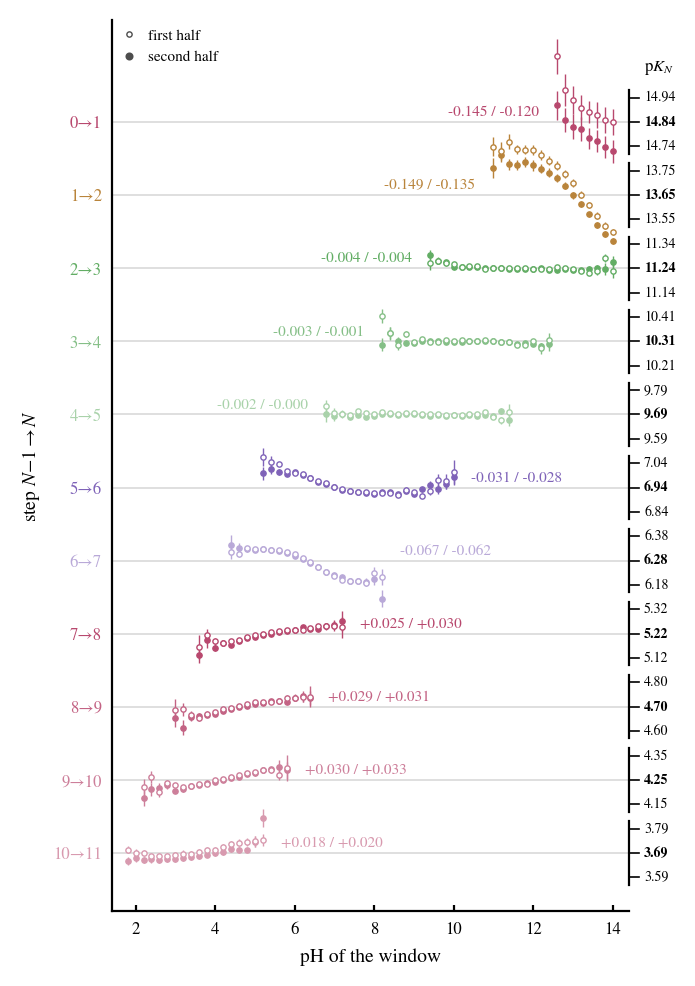

In [27]:
c = cons["native"]
hb = h32["native"]
nb = hb.shape[1]
pK_half, se_half = [], []
for sl in (slice(0, nb // 2), slice(nb // 2, nb)):
    pk, se, _ = prime.stepwise_pka(hb[:, sl].sum(axis=1), pHs, h_blk=hb[:, sl], n_boot=400, min_count=1, max_se=np.inf)
    pK_half.append(pk)
    se_half.append(se)


def weighted_slope(x, y, w):
    A = np.vstack([np.ones_like(x), x]).T
    cov = np.linalg.inv(A.T @ (w[:, None] * A))
    b = cov @ (A.T @ (w * y))
    return b[1], np.sqrt(cov[1, 1])


R = strips_input(c)
slopes = {}
print(f"{'step':>7} {'slope, first half':>20} {'slope, second half':>20} {'RMS z(first - second)':>22}   (pK units per pH unit)")
for j in R["rows"]:
    m = c["usable"][:, j]
    fit = []
    for pk, se in zip(pK_half, se_half):
        ok = m & np.isfinite(pk[:, j]) & np.isfinite(se[:, j]) & (se[:, j] > 0)
        fit.append(weighted_slope(pHs[ok], pk[ok, j], 1.0 / se[ok, j] ** 2) if ok.sum() > 2 else (np.nan, np.nan))
    d = pK_half[0][:, j] - pK_half[1][:, j]
    z = d / np.sqrt(se_half[0][:, j] ** 2 + se_half[1][:, j] ** 2)
    slopes[j] = fit
    print(f"{c['steps'][j] - 1:>3d}->{c['steps'][j]:<3d} {fit[0][0]:+.4f} ± {fit[0][1]:.4f}    {fit[1][0]:+.4f} ± {fit[1][1]:.4f}    "
          f"{np.sqrt(np.nanmean(z[m] ** 2)):>18.2f}")

sets = []
for i, hollow in ((0, True), (1, False)):                    # first half open, second half filled
    mask = c["usable"] & np.isfinite(pK_half[i]) & np.isfinite(se_half[i])
    sets.append((pK_half[i] - c["pK_mean"][None, :], se_half[i], mask, hollow))
fig, ax = plt.subplots(figsize=(3.4, 0.40 * len(R["rows"]) + 0.5), dpi=200)
draw_strips(ax, R, R["rows"], sets, lambda j: f"{slopes[j][0][0]:+.3f} / {slopes[j][1][0]:+.3f}")
ax.set_ylim(top=(len(R["rows"]) - 1) * OFF + OFF * 1.4)          # room for the topmost strip and the legend
ax.plot([], [], "o", ms=1.9, mfc="white", mec="0.3", mew=0.5, ls="none", label="first half")
ax.plot([], [], "o", ms=1.9, color="0.3", ls="none", label="second half")
ax.legend(loc="upper left", frameon=False, fontsize=FS - 1.5, handlelength=1.0, borderaxespad=0.2)
fig.subplots_adjust(left=0.14, right=0.9, top=0.99, bottom=0.08)
fig.savefig(f"{FIG_DIR}/Consistency_strips_halves.pdf", bbox_inches="tight")
plt.show()

### The test on the other runs of the monomer

The excess scatter of every step in the runs at the other restraint weights and in the unrestrained run, against the reported run.

In [28]:
c10 = cons["native"]
rows = [int(j) for j in np.flatnonzero(c10["n_windows"] >= 2)]
print(f"{'step':>7} " + "".join(f"{'tau, ' + ('none' if w == 0 else f'{w:g}'):>12}" for w in runs))
for j in rows:
    print(f"{c10['steps'][j] - 1:>3d}->{c10['steps'][j]:<3d} " + "".join(f"{runs[w]['consistency']['tau'][j]:>12.3f}" for w in runs))
for w in runs:
    if w != 10:
        d = np.abs(runs[w]["consistency"]["tau"][rows] - c10["tau"][rows])
        print(f"weight {'none' if w == 0 else f'{w:g}'}: |tau - tau(10)| up to {np.nanmax(d):.3f} pK units, largest tau {np.nanmax(runs[w]['consistency']['tau'][rows]):.3f}")

   step      tau, 10      tau, 1    tau, 0.1   tau, none
  0->1          0.048       0.060       0.029       0.000
  1->2          0.123       0.110       0.110       0.000
  2->3          0.003       0.006       0.006       0.006
  3->4          0.002       0.005       0.005       0.007
  4->5          0.000       0.010       0.014       0.021
  5->6          0.026       0.019       0.027       0.027
  6->7          0.038       0.029       0.041       0.024
  7->8          0.018       0.019       0.021       0.021
  8->9          0.020       0.018       0.019       0.020
  9->10         0.024       0.021       0.020       0.014
 10->11         0.019       0.016       0.012       0.012
weight 1: |tau - tau(10)| up to 0.013 pK units, largest tau 0.110
weight 0.1: |tau - tau(10)| up to 0.018 pK units, largest tau 0.110
weight none: |tau - tau(10)| up to 0.123 pK units, largest tau 0.027


## 7. TOC graphic, `TOC_graphic.pdf`

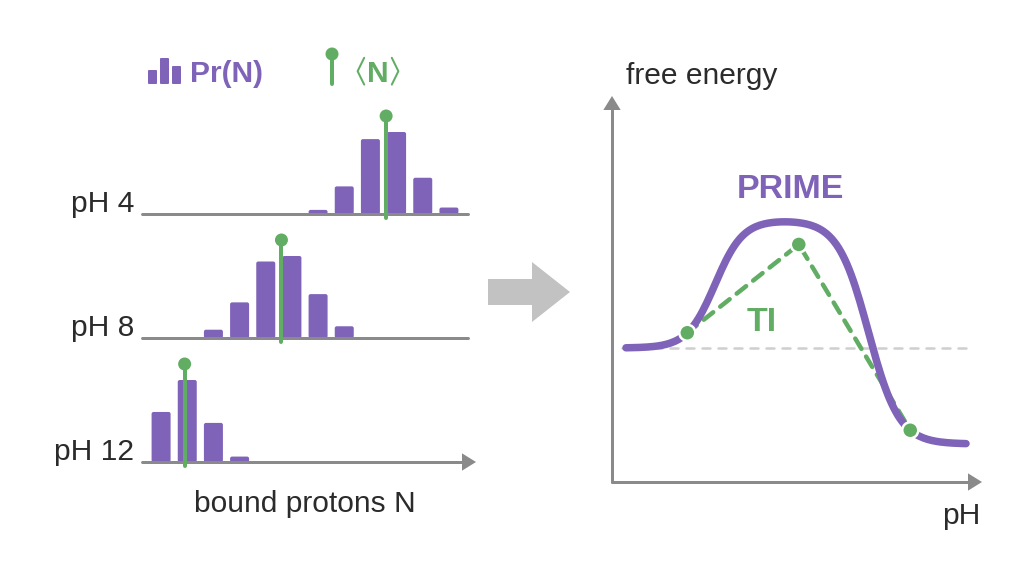

In [29]:
TOC_COLORS = (COLORS[0], COLORS[1])                   # PRIME and TI as in the figures (TI trapezoid)
TOC_WINDOWS = (("pH 4", 4.0, 8.6, 1.05),              # label, pH, mean and width of the histogram of N
               ("pH 8", 8.0, 4.6, 1.20),
               ("pH 12", 12.0, 0.9, 0.90))
TI_DROP = (0.0, 0.17, 0.0)                            # TI below the PRIME curve at each window, in plateau heights
TOC_FONT = next(f for f in ("Helvetica", "Arial", "Liberation Sans", "TeX Gyre Heros", "DejaVu Sans")
                if f in {font.name for font in font_manager.fontManager.ttflist})


def toc_graphic(stem):
    '''Draw the graphic and save it as stem.svg, stem.pdf, stem.png and stem.tiff.'''
    C_PRIME, C_TI = TOC_COLORS
    INK, GRAY, GRAY_LIGHT, GRAY_ARROW = "#2b2b2b", "#8a8a8a", "#cfcfcf", "#c2c2c2"
    W, H = 975, 525                                   # 3.25 x 1.75 in at 300 dpi
    PX = 72 / 300                                     # one pixel in points (font sizes and line widths)
    F_LABEL, F_NAME = 30, 34                          # font sizes in px, 7.2 pt and 8.2 pt (ACS asks for 6 pt or more)

    fig = plt.figure(figsize=(W / 300, H / 300), dpi=300)
    fig.patch.set_facecolor("white")
    ax = fig.add_axes([0, 0, 1, 1])
    ax.set_xlim(0, W)
    ax.set_ylim(H, 0)
    ax.axis("off")

    def stroke(x, y, color, w, z, dash=None):
        ls = "-" if dash is None else (0, (dash[0] / w, dash[1] / w))
        ax.plot(x, y, color=color, lw=w * PX, ls=ls, zorder=z, solid_capstyle="round", solid_joinstyle="round",
                dash_capstyle="round", dash_joinstyle="round")

    def bar(x, y_base, w, h, color, z, r=2):
        ax.add_patch(FancyBboxPatch((x - w / 2, y_base - h), w, h, boxstyle=f"round,pad=0,rounding_size={r}",
                                    fc=color, ec="none", zorder=z))

    def disc(x, y, r, color, z, rim=0.0):
        ax.add_patch(Circle((x, y), r, fc=color, ec="white" if rim else "none", lw=rim * PX, zorder=z))

    def arrow(x1, y1, x2, y2, color, w, head, z):
        t = np.array([x2 - x1, y2 - y1]) / np.hypot(x2 - x1, y2 - y1)
        base = np.array([x2, y2]) - head * t
        side = 0.62 * head * np.array([-t[1], t[0]])
        stroke([x1, base[0]], [y1, base[1]], color, w, z)
        ax.add_patch(Polygon([(x2, y2), base + side, base - side], closed=True, fc=color, ec="none", zorder=z))

    def label(x, y, s, size=F_LABEL, color=INK, ha="left", bold=False):
        ax.text(x, y, s, fontsize=size * PX, color=color, ha=ha, va="baseline",
                fontweight="bold" if bold else "normal", zorder=6)

    def mean_label(x, y, size, color):
        label(x, y, "N", size, color, ha="center", bold=True)
        cap, tip, half = 0.72 * size, 0.46 * size, 0.22 * size
        for s in (-1, 1):
            stroke([x + s * tip, x + s * (tip + half), x + s * tip],
                   [y - 1.12 * cap, y - 0.5 * cap, y + 0.12 * cap], color, max(2.0, 0.065 * size), 6)

    # left: the three windows
    N_SITES_TOC = 11
    X_N0, X_N1 = 118, 432
    PITCH = (X_N1 - X_N0) / (N_SITES_TOC + 1)
    BAR_W, BAR_H = 19, 82
    BASELINES = (184, 308, 432)
    N_grid = np.arange(N_SITES_TOC + 1)

    def x_of_N(N):
        return X_N0 + (N + 0.5) * PITCH

    Y_KEY = 54
    for i, h in enumerate((14, 26, 18)):
        bar(122.5 + 12 * i, Y_KEY, 9, h, C_PRIME, 2, r=1)
    label(160, Y_KEY - 2, "Pr(N)", color=C_PRIME, bold=True)
    stroke([302, 302], [Y_KEY, Y_KEY - 30], C_TI, 4, 4)
    disc(302, Y_KEY - 30, 6.5, C_TI, 5)
    mean_label(348, Y_KEY - 2, F_LABEL, C_TI)

    for (name, _, mean, width), y0 in zip(TOC_WINDOWS, BASELINES):
        label(104, y0 - 2, name, ha="right")
        weight = np.exp(-0.5 * ((N_grid - mean) / width) ** 2)
        heights = BAR_H * weight / weight.max()
        for N, h in zip(N_grid, heights):
            if h >= 2.0:
                bar(x_of_N(N), y0, BAR_W, h, C_PRIME, 2)
        if y0 == BASELINES[-1]:
            arrow(X_N0 - 6, y0, X_N1 + 14, y0, GRAY, 3, 14, 3)
        else:
            stroke([X_N0 - 6, X_N1 + 6], [y0, y0], GRAY, 3, 3)
        stroke([x_of_N(mean)] * 2, [y0 + 4, y0 - BAR_H - 16], C_TI, 4, 4)
        disc(x_of_N(mean), y0 - BAR_H - 16, 6.5, C_TI, 5)
    label((X_N0 + X_N1) / 2, 482, "bound protons N", ha="center")

    ax.add_patch(Polygon([(458, 249), (502, 249), (502, 232), (540, 262), (502, 292), (502, 275), (458, 275)],
                         closed=True, fc=GRAY_ARROW, ec="none", zorder=2))

    # right: free energy against pH
    X_AX, Y_AX, X_END, Y_TOP = 582, 452, 952, 66
    X_PH0, X_PH1, PH0, PH1 = 596, 936, 1.8, 14.0
    Y_ZERO, SCALE = 318, 128

    def free_energy(pH):
        return 1.0 / (1.0 + np.exp(-(pH - 5.0) / 0.5)) - 1.75 / (1.0 + np.exp(-(pH - 10.5) / 0.55))

    def x_of_pH(pH):
        return X_PH0 + (np.asarray(pH) - PH0) / (PH1 - PH0) * (X_PH1 - X_PH0)

    def y_of_G(G):
        return Y_ZERO - SCALE * np.asarray(G)

    arrow(X_AX, Y_AX, X_AX, Y_TOP, GRAY, 3, 14, 3)
    arrow(X_AX, Y_AX, X_END, Y_AX, GRAY, 3, 14, 3)
    stroke([X_PH0 - 4, X_PH1 + 4], [Y_ZERO, Y_ZERO], GRAY_LIGHT, 2.5, 1, dash=(8, 8))
    label(X_AX + 14, Y_TOP - 12, "free energy")
    label(X_END - 2, Y_AX + 42, "pH", ha="right")

    pH_fine = np.linspace(PH0, PH1, 161)
    pH_win = np.array([window[1] for window in TOC_WINDOWS])
    G_TI = free_energy(pH_win) - np.array(TI_DROP)
    stroke(x_of_pH(pH_win), y_of_G(G_TI), C_TI, 4.5, 3, dash=(12, 9))
    stroke(x_of_pH(pH_fine), y_of_G(free_energy(pH_fine)), C_PRIME, 7.5, 4)
    for x, y in zip(x_of_pH(pH_win), y_of_G(G_TI)):
        disc(x, y, 8, C_TI, 5, rim=2.5)
    label(760, 168, "PRIME", F_NAME, C_PRIME, ha="center", bold=True)
    label(732, 301, "TI", F_NAME, C_TI, ha="center", bold=True)

    for ext in ("svg", "pdf", "png"):
        fig.savefig(f"{stem}.{ext}", dpi=300, facecolor="white")
    Image.open(f"{stem}.png").convert("RGB").save(f"{stem}.tiff", dpi=(300, 300), compression="tiff_lzw")
    plt.show()


with plt.rc_context({"font.family": TOC_FONT, "lines.scale_dashes": True, "savefig.bbox": "standard"}):
    toc_graphic(f"{FIG_DIR}/TOC_graphic")